# Physics Baseline

In [1]:
import os
import glob
import numpy as np
np.random.seed(12345)
import pandas as pd

import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import re
import warnings
warnings.filterwarnings('ignore')

In [2]:
# Automatically detect if running on Kaggle or Locally
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'

print(f"Running on {'Kaggle' if IS_KAGGLE else 'Local Environment'}")
print(f"Data Directory: {BASE_DIR}")
train_data = os.path.join(BASE_DIR, "train")
file_paths = sorted(os.listdir(train_data))
file_paths[:10]

Running on Local Environment
Data Directory: ../data


['000d7d20.png',
 '000d7d20__horizontal_well.csv',
 '000d7d20__typewell.csv',
 '00bbac68.png',
 '00bbac68__horizontal_well.csv',
 '00bbac68__typewell.csv',
 '00e12e8b.png',
 '00e12e8b__horizontal_well.csv',
 '00e12e8b__typewell.csv',
 '015fe0d2.png']

In [3]:
# Regex pattern: 
pattern = re.compile(r'([^/\\]+)__horizontal_well\.csv')

well_names = []
for path in file_paths:
    match = pattern.search(path)
    if match:
        well_names.append(match.group(1))

print("Extracted Well Names:")
print(len(well_names), "Well Names")

Extracted Well Names:
773 Well Names


In [4]:
from scipy.signal import butter, filtfilt
def remove_rotation_noise(gr_series, cutoff):
    """
    Low pass filter.
    """
    # 1. Handle NaNs safely
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    
    # 2. Design the Butterworth Filter
    # Nyquist frequency is 0.5 (half of our 1-foot sample rate)
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    
    # Order 4 is strong enough to kill the noise without distorting the geology
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    
    # 3. Apply Zero-Phase Filtering
    gr_clean = filtfilt(b, a, gr_filled)
    
    # Put the NaNs back exactly where they were originally (if you need them)
    # gr_clean[gr_series.isna()] = np.nan 
    
    return gr_clean

from scipy.signal import find_peaks as p
def find_peaks(x_, y_, prominence, distance):

    # x = x_.copy().reset_index(drop=True)
    # y = y_.copy().reset_index(drop=True)
    
    # 2. Find the Prominent Peaks
    # The 'prominence' value requires tuning based on your specific data's scale.
    # 'distance' ensures you don't get two peaks right next to each other.
    peaks, properties = p(y, prominence=prominence, distance=distance)
    
    # 3. Calculate the boundaries (midpoints between major peaks)
    # We add the very beginning (0) and very end (length of array) to the boundaries
    midpoints = (peaks[:-1] + peaks[1:]) // 2
    boundaries = [0] + midpoints.tolist() + [len(y)]

    return peaks, properties, midpoints, boundaries
    

In [5]:
well = np.random.choice(well_names)
well = 'a3518960'

hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
tw = pd.read_csv(train_data + f"/{well}__typewell.csv")
pic = train_data + f"/{well}.png"

# Good Scoring:
'729f4217'
'ff0aea78'
# Bad Scoring:
'493b5b31: 180 API centre peak breaking everything'
'8f201368: Multiple Breaks without Peaks in the beginning'
'c99f9fae: Bad Ending' 
'2e63d9de: Unable to capture the rising TVT, one crest behind'
'511e1db0: One crest fails to match, rest gets matched'
'7d50373e: Fails to match, bad score'
'9c350a6a: Bad Score'
'7224331b: Bad Score: It seems to use the wrong curve after 17100'
'ccedb12b: 15 feet vertical TVT jump'
'SVG Failed to Converge'
'fef8af96: Bad Score'
'6d6d93af: Centre peaks dont get picked'

# Weird Values
'91b301ce: High TVT Range', 
'5f4d2a52: VERY bad score, doesnt have GR peaks in the beginning, has plain start with 150 API peaks at the end'
'ba48188d, 91b301ce, 5f4d2a52: High STD for TVT: 30-35, next is 26'

'a3518960: Shows discontinuity can exist'


well, hw.shape, tw.shape

('a3518960', (6992, 13), (5137, 3))

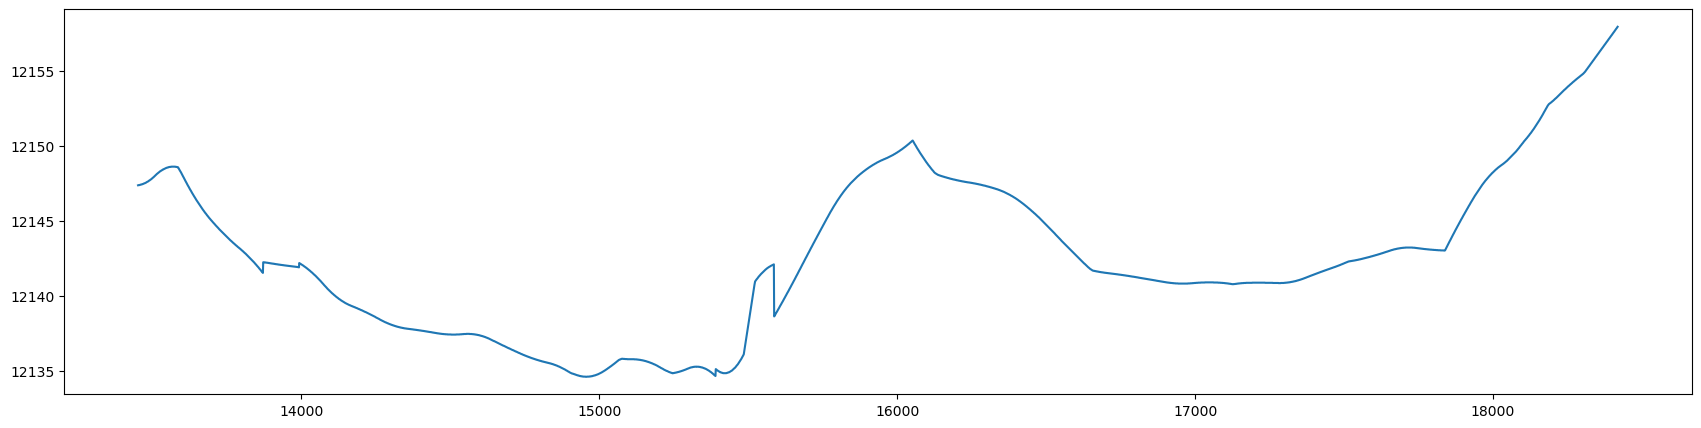

In [6]:
evalz = hw[hw['TVT_input'].isna()]
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'])  

In [7]:
HW_LOW_PASS_CUTOFF = 0.009
PEAK_PROMINENCE = 3.0
PEAK_DISTANCE = 50
EXTRA_DIVISIONS = [20, 70, 150]

fill = lambda df: df.interpolate(method='linear', limit_direction='both')
d = lambda df: fill(df).diff().rolling(11, center=True, min_periods=1).mean()

(30, 4967)

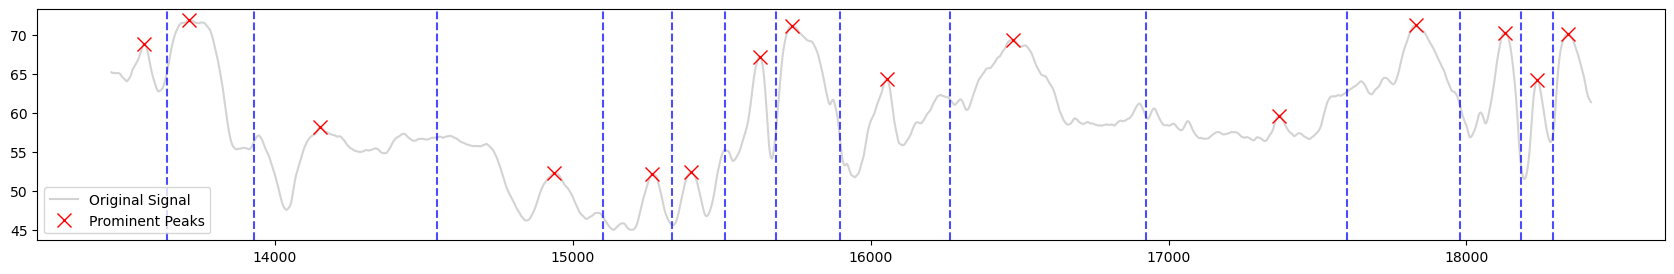

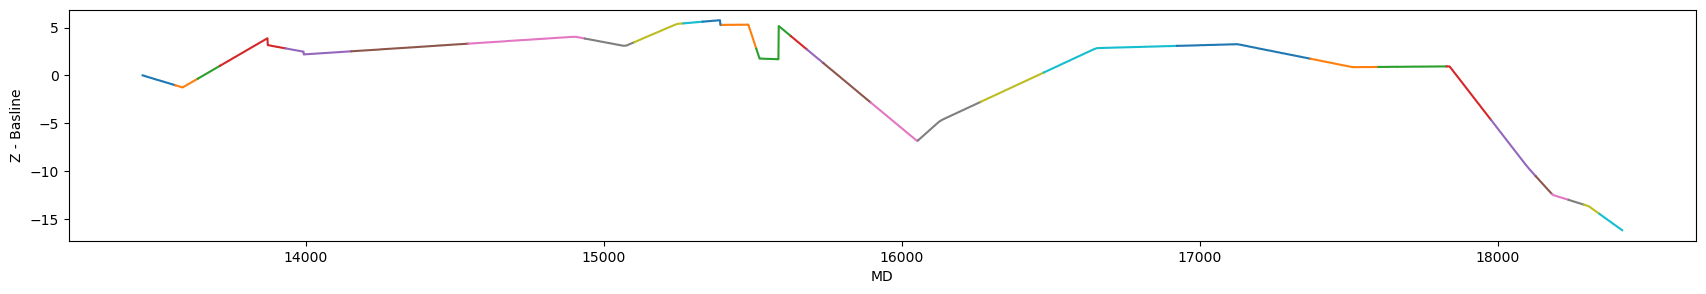

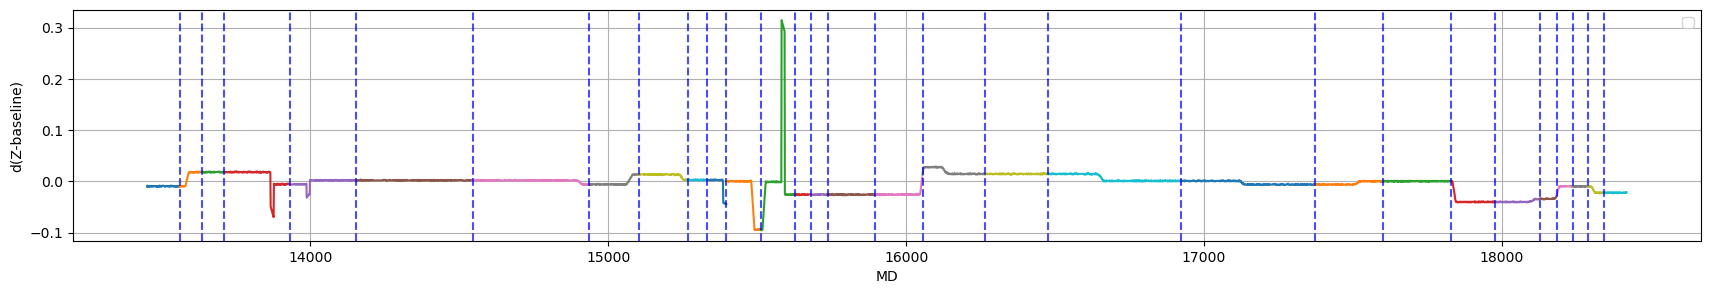

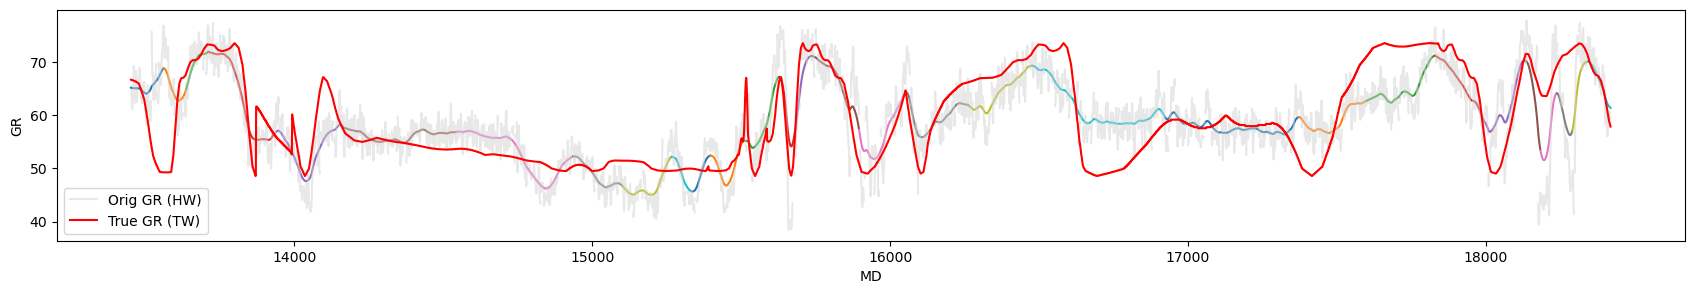

<Figure size 2100x300 with 0 Axes>

In [8]:
# Only to predict
mask = hw['TVT_input'].isna()
evalz = hw[mask].copy()

# Normalizing stuff
slope, intercept = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
pred = evalz['Z'] - evalz['MD'] * slope - intercept
pred_norm = pred - pred.iloc[0] 
tvt_norm = -evalz['TVT'] + evalz['TVT'].iloc[0]
evalz['norm_TVT'] = tvt_norm
evalz['norm_Z'] = pred_norm
evalz['Z-bl'] = evalz['norm_TVT'] - evalz['norm_Z']
evalz['GR'] = remove_rotation_noise(evalz['GR'], cutoff=HW_LOW_PASS_CUTOFF)
evalz['dZ-bl'] = d(evalz['Z-bl'])

# Making Chunks Containing major peaks in GR
plt.figure(figsize = (21, 3))
x = evalz['MD'].copy().reset_index(drop=True)
y = evalz['GR'].copy().reset_index(drop=True)
peaks, properties, midpoints, boundaries = find_peaks(x, y, prominence=PEAK_PROMINENCE, distance=PEAK_DISTANCE)
plt.plot(x, y, color='lightgrey', label='Original Signal')
plt.plot(x[peaks], y[peaks], "x", color='red', markersize=10, label='Prominent Peaks')
plt.legend()
for i in range(len(boundaries) - 1):
    start_idx = boundaries[i]
    end_idx = boundaries[i+1]
    x_chopped = x[start_idx:end_idx]
    y_chopped = y[start_idx:end_idx]
    if i > 0:
        plt.axvline(x=x[start_idx], color='blue', linestyle='--', alpha=0.7)
        
# Adding Maximas/Minimas as well 
boundaries += (peaks.tolist())

# Adding Special Starting Divisions
for extra in EXTRA_DIVISIONS:
    # Check if there is any existing boundary 'b' where the distance 
    # to 'extra' is 50 or less (not strictly greater than 50)
    if all(abs(extra - b) > PEAK_DISTANCE for b in boundaries):
        boundaries.append(extra)

boundaries.sort()
chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries)-1)]

# Z-TVT
plt.figure(figsize=(21, 3))
for chunk in chunks:
    plt.plot(chunk['MD'], chunk['Z-bl'])    
plt.xlabel("MD")
plt.ylabel("Z - Basline")

# d(Z - baseline)
plt.figure(figsize = (21, 3))
for chunk in chunks:
    plt.plot(chunk['MD'], chunk['dZ-bl'])
plt.xlabel("MD")
plt.ylabel("d(Z-baseline)")
plt.grid(True)
plt.legend()
for i in range(len(boundaries) - 1):
    start_idx = boundaries[i]
    end_idx = boundaries[i+1]
    if i > 0:
        plt.axvline(x=x[start_idx], color='blue', linestyle='--', alpha=0.7)

# GR vs GR
plt.figure(figsize=(21, 3))
for chunk in chunks:
    plt.plot(chunk['MD'], chunk['GR'])
# gr = np.interp(hw[mask]['TVT'], tw['TVT'], remove_rotation_noise(tw['GR'], cutoff=0.05)) 
gr = np.interp(hw[mask]['TVT'], tw['TVT'], tw['GR']) 
plt.plot(evalz['MD'], hw[mask]['GR'], color='lightgray', label="Orig GR (HW)", alpha=0.5)
plt.plot(evalz['MD'], gr, color='red', label="True GR (TW)")
plt.xlabel("MD")
plt.ylabel("GR")
plt.legend()

plt.figure(figsize=(21, 3))
# plt.plot(evalz['MD'], evalz['norm_Z'])
# m, c = np.polyfit(evalz['MD'], evalz['Y'], deg=1)
# plt.plot(evalz['MD'], evalz['Y'] - m * evalz['MD'] - c)
# plt.plot(evalz[

len(chunks), len(evalz)

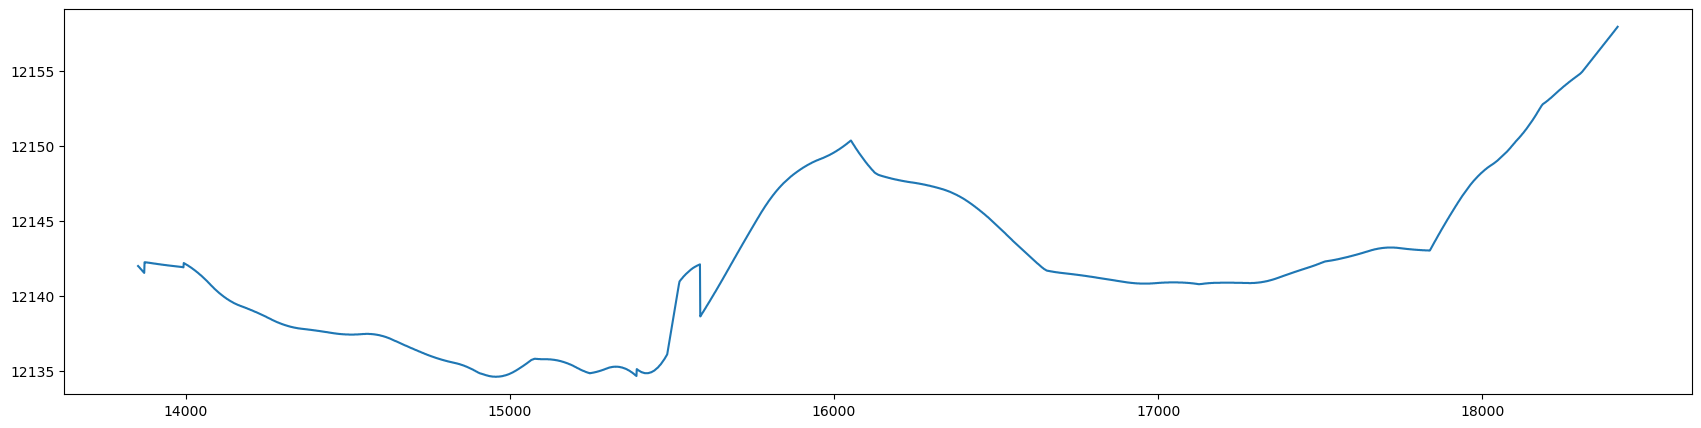

In [9]:
evalz = evalz[400:]
plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'])  

(12041.990000000002, 12241.990000000002)

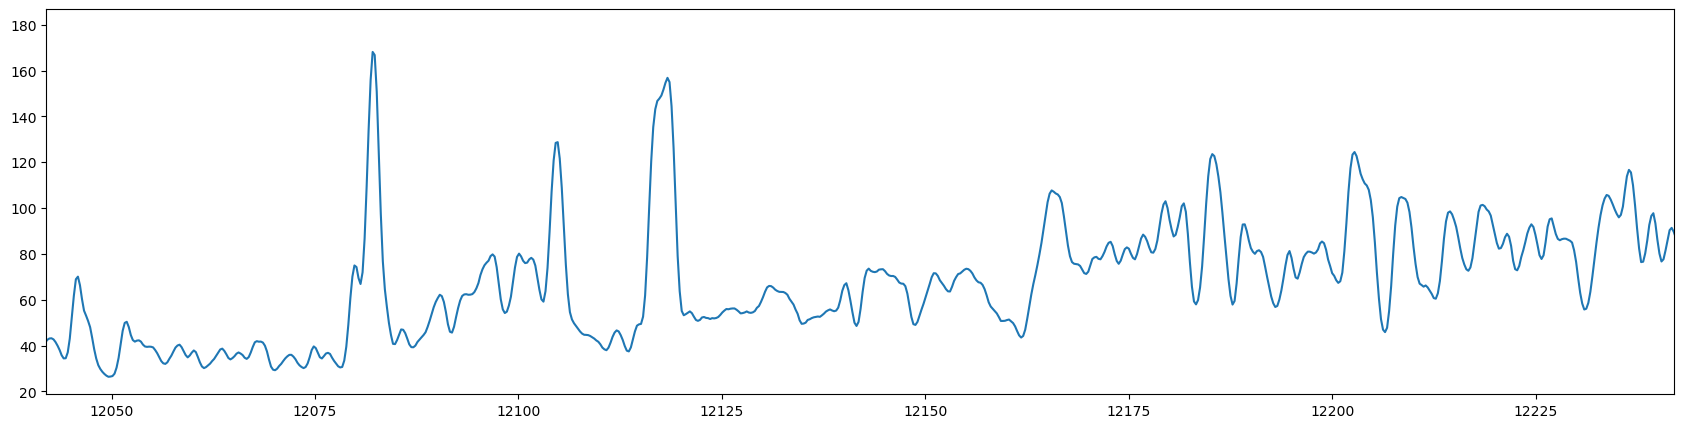

In [10]:
plt.figure(figsize=(21, 5))
plt.plot(tw['TVT'], tw['GR'])
tvt0 = evalz['TVT'].iloc[0]
plt.xlim(tvt0 - 100, tvt0 + 100)

## Hypothesis:
* Star steer calculates $TVT - TVT_0 = |Z| - |Z_0| - (m * MD + c)$ for every chunk
    * Absolute Space &rarr; Stratigraphic Space
    * Where $m and c$ are optimized to have the best $GR$ wave match using this chunk and the other chunks
    * The $TVT_0$ for the other chunk is choosen to be the last predicted $TVT$ in the chunk

## Flow:
* Find how division in chunks could be replicated close to the geologist's division.
    * Making chunks on the basis of points of inflection/maximas/minimas/their midpoints.
* You have $TVT_{start}$ with $Z_{start}$ and $Z_{end}$ for a chunk.
* You want $TVT_{b/w}$
    * Such that the points with $start$ and $end$ form a straight line in TVT + Z vs MD.
    * Match GR
        * ME: Such that the interp from tw is maximized in correlation with GR in the chunk. Matching GR vs MD
        * Geologist: Mathing bit by bit the GR of hw to tw's. Matching GR vs TVT
* Match GR vs np.interp(TVT) from Zi to Zi + 1, hence get TVTi + 1
* $ TVT = m * (Z - Z_i) + TVT_i $

* Using beam search

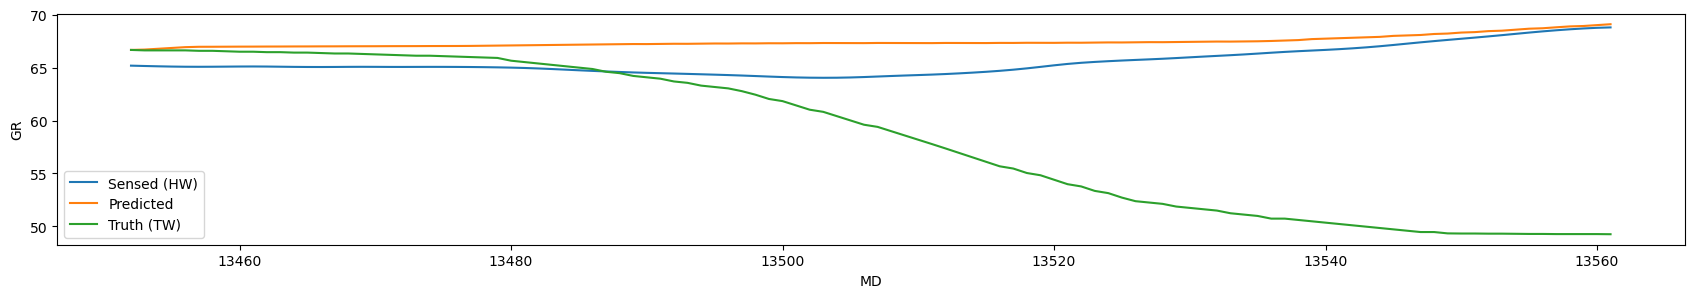

In [783]:
tvt_0 = chunks[0]['TVT'].iloc[0]
for chunk in chunks:
    plt.figure(figsize=(21, 3))
    md_0 = chunk['MD'].iloc[0]
    plt.plot(chunk['MD'], chunk['GR'], label='Sensed (HW)')

    ms = [0.05, 0.04, 0.03, 0.02, 0.01, 0, -0.01, -0.02, -0.03, -0.04, -0.05]
    m = -0.01 # Tunable
    tvt = m * (chunk['MD'] - md_0) - (chunk['norm_Z'] - chunk['norm_Z'].iloc[0]) + tvt_0
    tvt_0 = tvt.iloc[-1]
    gr = np.interp(tvt, tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], gr, label="Predicted")
    
    gr = np.interp(chunk['TVT'], tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], gr, label="Truth (TW)")
    
    plt.xlabel("MD")
    plt.ylabel("GR")
    plt.legend()
    break

In [784]:
chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries)-1)]
ms = list()
cs = list()
for chunk in chunks:
    # plt.plot(chunk['MD'], chunk['Z-bl'])
    m, c = np.polyfit(chunk['MD'] - chunk['MD'].iloc[0], chunk['Z-bl'] - chunk['Z-bl'].iloc[0], deg=1)
    ms.append(m.round(3))
    cs.append(c.round(3))

plt.figure(figsize=(21, 5))
plt.plot(ms, label='ms')
plt.legend()
plt.figure(figsize=(21, 5))
plt.plot(cs, label='cs')
plt.legend()

IndexError: single positional indexer is out-of-bounds

In [785]:
from scipy.optimize import minimize
from scipy.stats import pearsonr

# Params to tune
MS = [0.07, 0.05, 0.03, 0.01, 0, -0.01, -0.03, -0.05, -0.07]
# CS = [-0.1, 0, 0.1]
CS = [0]

BEAM_WIDTH = 30 

M_RANGE, C_RANGE = ((-0.05, 0.05), (-0.5, 0.5))
# M_RANGE, C_RANGE = ((-0.1, 0.1), (-0.001, 0.001))

PEAK_GR_STD = float('-inf')
PEAK_GR_STD = float('+inf')

JUMPS = [10, 20, 30, 40, 50, 60]
# JUMPS = []
C_JUMPS = [-7,-3, 3, 7]

In [786]:
chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries) - 1)]

initial_tvt_0 = hw[~mask]['TVT'].iloc[-1]

# Define the dynamic cost function for the optimizer
def shape_aware_cost(params, chunk, md_0, current_tvt_0):
    m_cand, c_cand = params
    tvt_cand = m_cand * (chunk['MD'] - md_0) - (chunk['norm_Z'] - chunk['norm_Z'].iloc[0]) + current_tvt_0 + c_cand
    gr_cand = np.interp(tvt_cand, tw['TVT'], tw['GR']) 
    
    # Filter valid data points
    valid = ~np.isnan(chunk['GR']) & ~np.isnan(gr_cand)
    if np.sum(valid) < 10:
        return 1e6 # Heavy penalty for invalid/empty overlaps

    gr_sensed = chunk['GR'][valid]
    gr_pred = gr_cand[valid]
    
    # Dynamic Routing: Check if chunk has a prominent peak using Standard Deviation
    # A standard deviation > 10 API usually indicates we are looking at a real geological feature
    if np.std(gr_sensed) > PEAK_GR_STD:
        # Prevent division by zero if the prediction is completely flat
        if np.std(gr_pred) < 1e-5:
            return 1e6 
            
        # Shape Matching: Maximize correlation coefficient (1.0 is perfect shape match)
        corr, _ = pearsonr(gr_sensed, gr_pred)
        
        # We return (1.0 - corr) because the optimizer wants to *minimize* the result
        return 1.0 - corr if not np.isnan(corr) else 1e6
    else:
        # Baseline Matching: Minimize MSE for flat/noisy shale sections
        return np.mean((gr_sensed - gr_pred)**2)

# Initialize beams. Each beam holds the state of a specific route through the chunks.
beams = [{
    "tvt_0": initial_tvt_0,
    "m_path": [],
    "c_path": [],
    "total_error": 0.0,
    "tvt_cands": [],
    "gr_cands": [],
    "opt_types": []
}]

# Iterate through the chunks using Beam Search + Continuous Optimization
for i, chunk in enumerate(chunks):
    md_0 = chunk['MD'].iloc[0]
    new_beams = []
    
    # Determine the optimization type for logging
    valid_gr = chunk['GR'].dropna()
    is_shape = np.std(valid_gr) > PEAK_GR_STD if len(valid_gr) > 0 else False
    opt_type = "Shape Correlation" if is_shape else "Baseline MSE"

    if i in JUMPS:
        c_jumps = C_JUMPS
    else:
        c_jumps = []
    
    for beam in beams:
        # 1. Find the continuous local optimum for this specific beam's trajectory
        for m0 in [-0.05, 0, 0.05]:
            res = minimize(
                shape_aware_cost,
                x0=[m0, 0.0],
                bounds=(M_RANGE, C_RANGE),
                args=(pd.concat(chunks[i:i+5]), md_0, beam["tvt_0"]),
                method='L-BFGS-B'
            )
            best_m_cont, best_c_cont = res.x
            
            # 2. Create branches: include the continuous optimum + the discrete grid look-ahead
            m_cands = list(set(MS + [best_m_cont]))
            c_cands = list(set(CS + [best_c_cont] + c_jumps))
        
        for m_cand in m_cands:
            for c_cand in c_cands:
                tvt_cand = m_cand * (chunk['MD'] - md_0) - (chunk['norm_Z'] - chunk['norm_Z'].iloc[0]) + beam["tvt_0"] + c_cand
                gr_cand = np.interp(tvt_cand, tw['TVT'], tw['GR']) 
                
                # Evaluate the shape-aware cost for this branch
                chunk_error = shape_aware_cost([m_cand, c_cand], chunk, md_0, beam["tvt_0"])
                
                new_beam = {
                    "tvt_0": tvt_cand.iloc[-1],
                    "m_path": beam["m_path"] + [m_cand],
                    "c_path": beam["c_path"] + [c_cand],
                    "total_error": beam["total_error"] + chunk_error,
                    "tvt_cands": beam["tvt_cands"] + [tvt_cand],
                    "gr_cands": beam["gr_cands"] + [gr_cand],
                    "opt_types": beam["opt_types"] + [opt_type]
                }
                new_beams.append(new_beam)
            
    # Sort and prune beams
    new_beams.sort(key=lambda x: x["total_error"])
    beams = new_beams[:BEAM_WIDTH]

# Extract the overall best path
best_overall_path = beams[0]
best_m_sequence = best_overall_path["m_path"]
best_c_sequence = best_overall_path["c_path"]
best_gr_sequence = best_overall_path["gr_cands"]
best_tvt_sequence = best_overall_path["tvt_cands"]
best_opt_sequence = best_overall_path["opt_types"]

# --- CALCULATE AND PRINT FINAL RMSE ---
final_tvt = pd.concat(best_tvt_sequence)
final_rmse = np.sqrt(np.nanmean((final_tvt - evalz['TVT'])**2))
print(f"Overall RMSE between Final Concatenated TVT and evalz['TVT']: {final_rmse:.6f}")

# --- PLOTTING THE OPTIMIZED CONTINUOUS RESULTS ---
for i, chunk in enumerate(chunks):
    plt.figure(figsize=(21, 3))
    
    best_m = best_m_sequence[i]
    best_c = best_c_sequence[i]
    best_pred_gr = best_gr_sequence[i]
    opt_type = best_opt_sequence[i]
    
    # Plotting the optimized results for this chunk
    plt.plot(chunk['MD'], chunk['GR'], label='Sensed (HW)')
    plt.plot(chunk['MD'], best_pred_gr, label=f"Predicted (m={best_m:.5f}, c={best_c:.2f})")
    
    truth_gr = np.interp(chunk['TVT'], tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], truth_gr, label="Truth (TW)", linestyle='--', alpha=0.7)
    
    plt.title(f"Chunk {i+1}: Optimized m = {best_m:.5f}, c = {best_c:.2f} (via {opt_type} + Beam Search)")
    plt.xlabel("MD")
    plt.ylabel("GR")
    plt.legend()

IndexError: single positional indexer is out-of-bounds

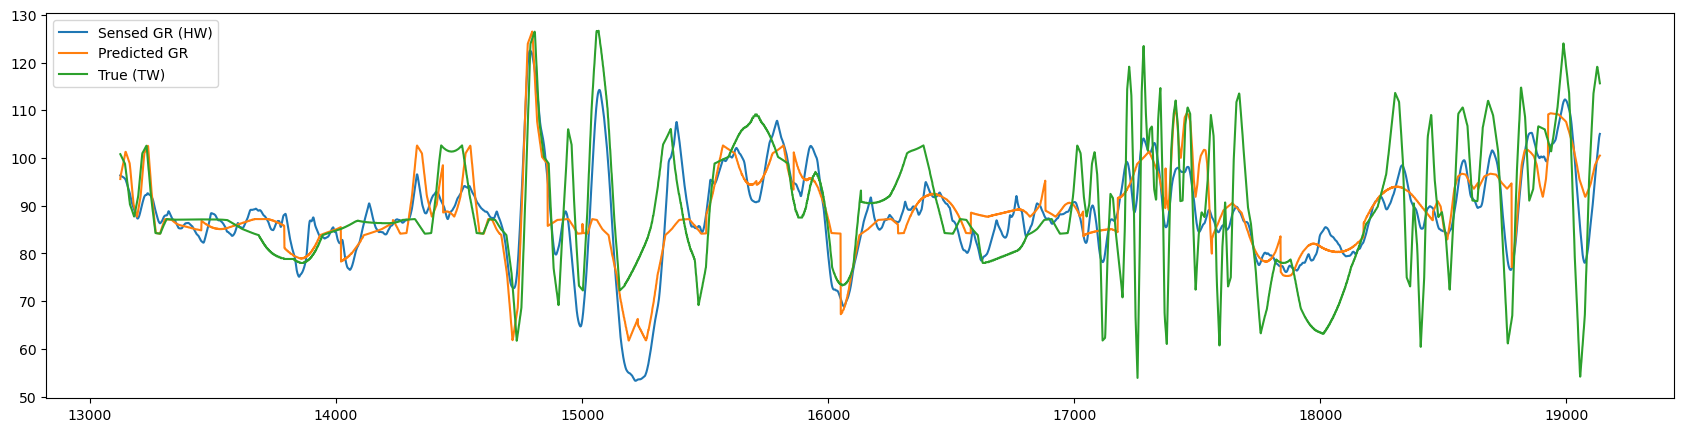

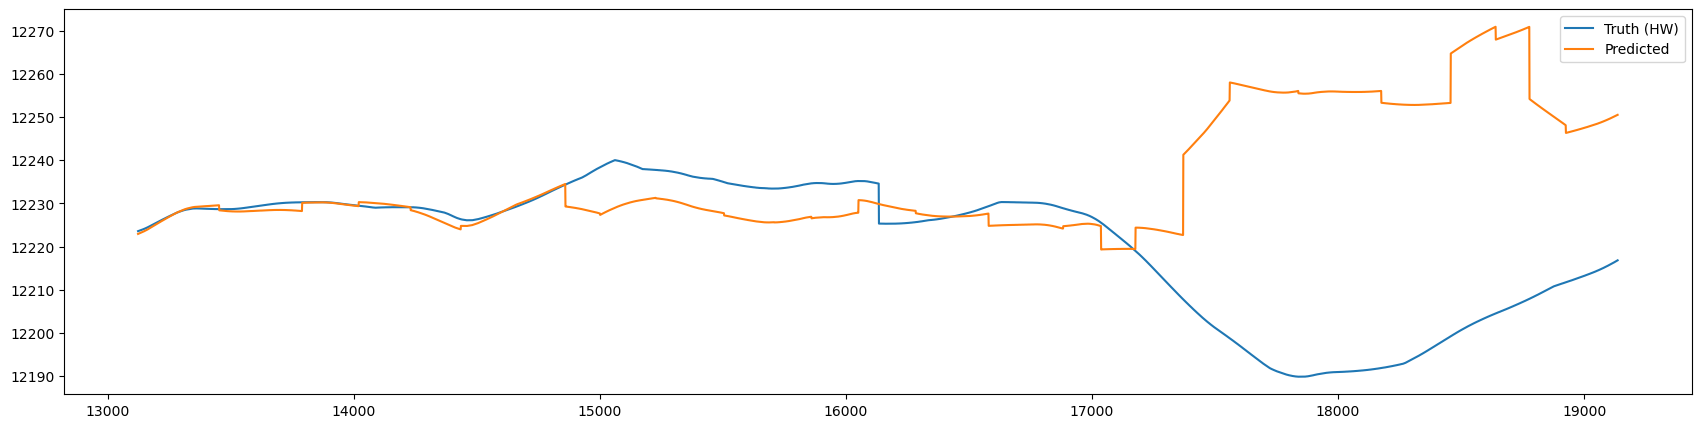

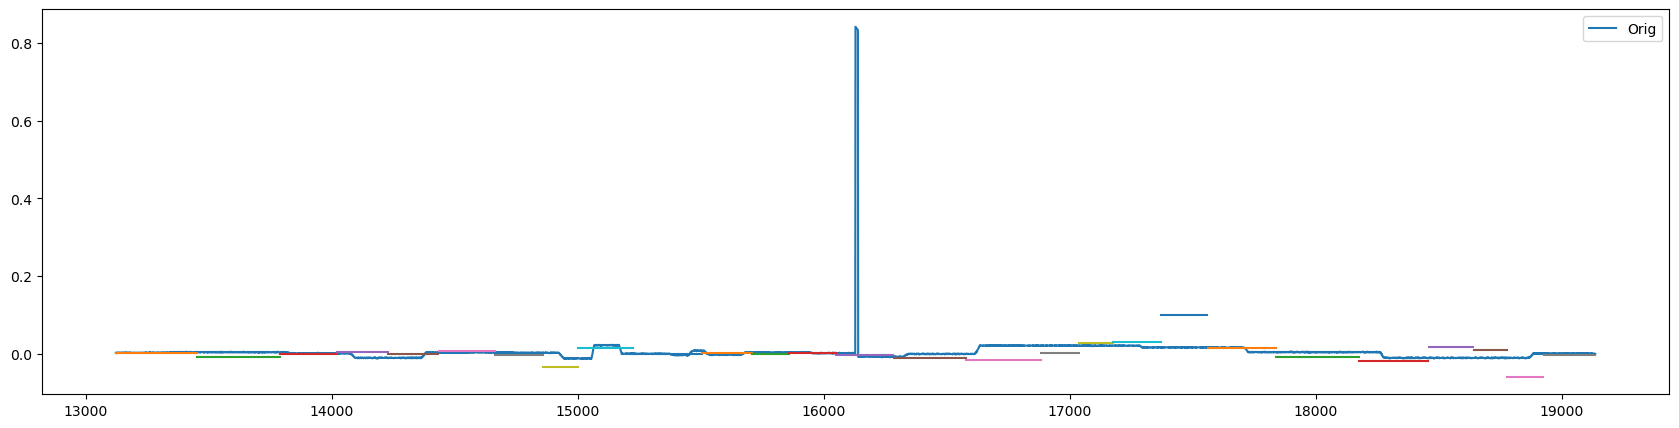

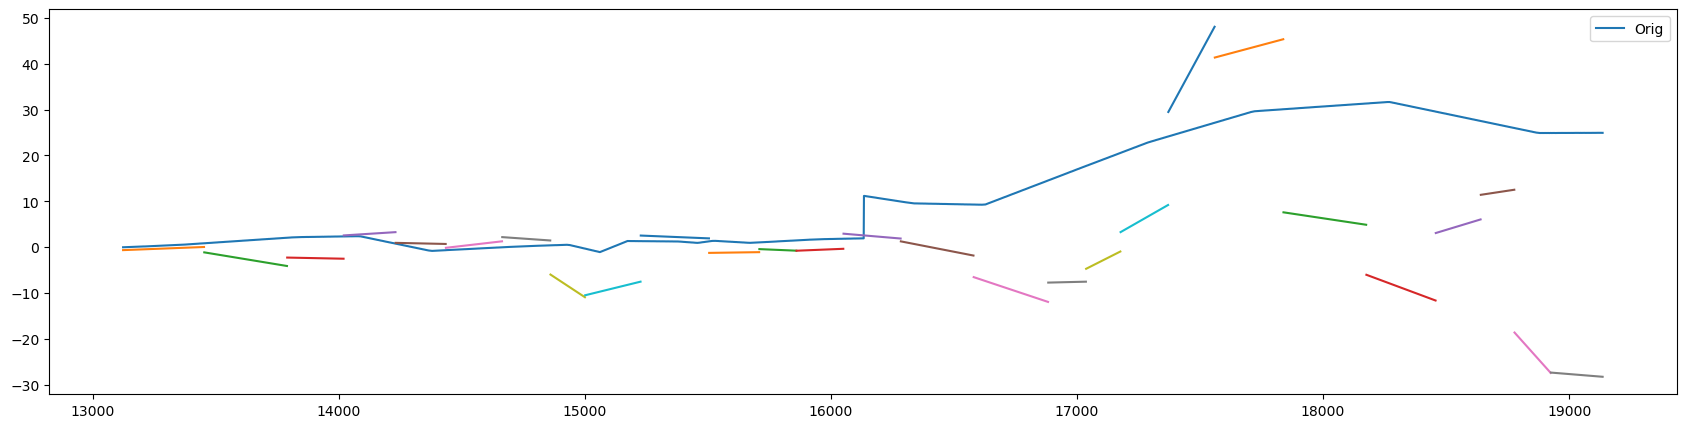

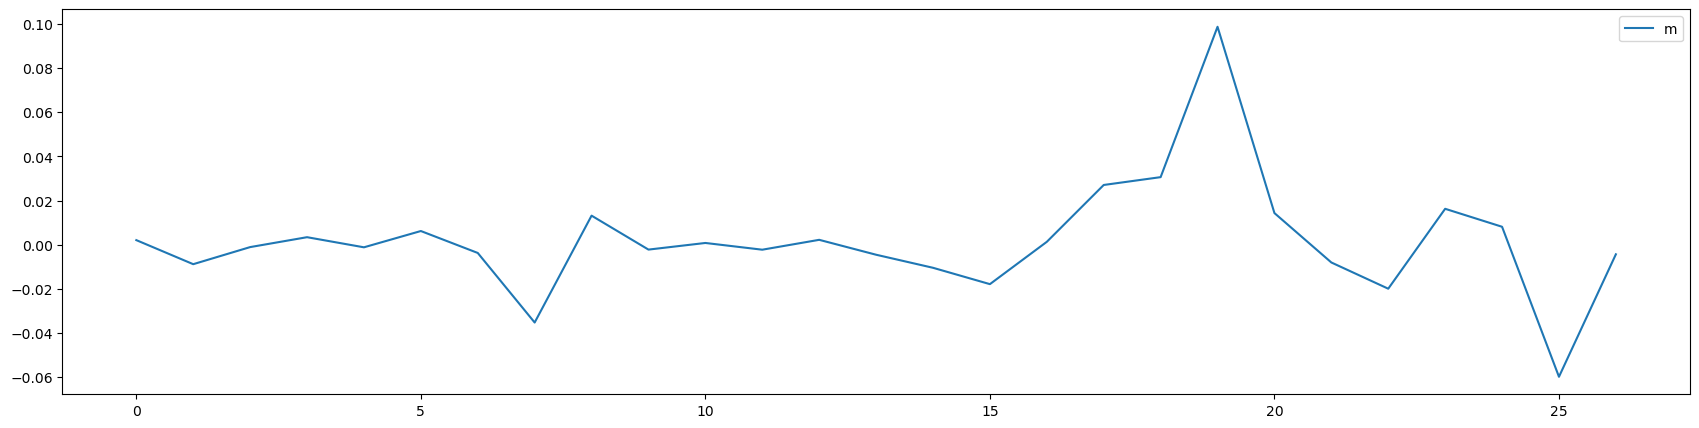

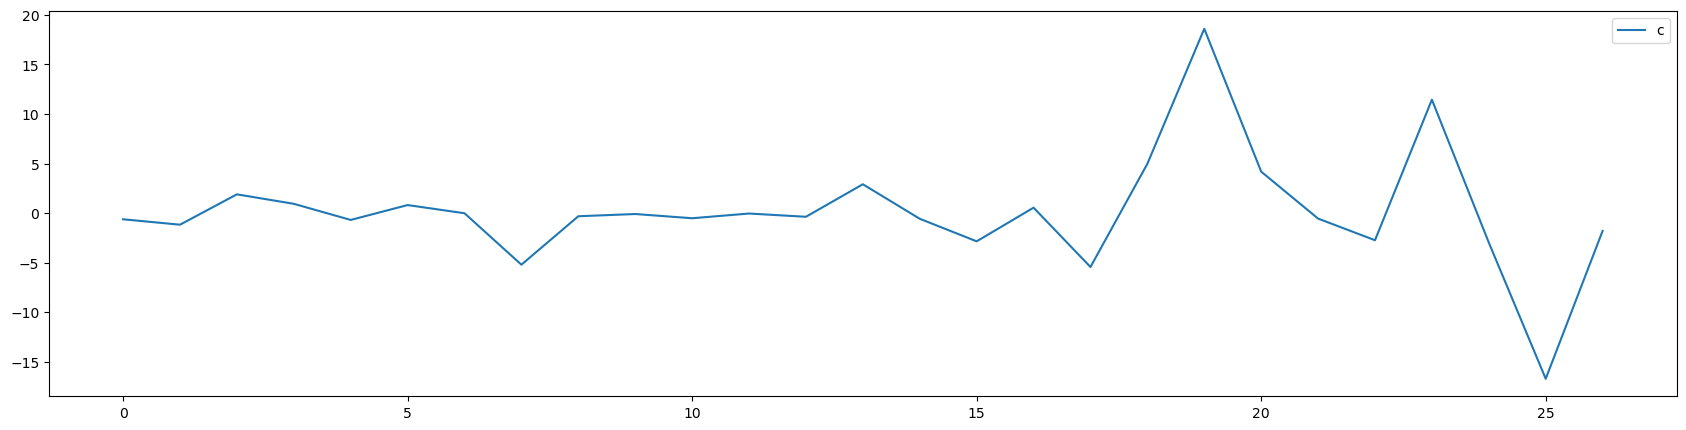

In [814]:
plt.figure(figsize=(21, 5))
gr = np.concat(best_gr_sequence)
plt.plot(evalz['MD'], evalz['GR'], label='Sensed GR (HW)')
plt.plot(evalz['MD'], gr, label='Predicted GR')
gr = np.interp(evalz['TVT'], tw['TVT'], tw['GR'])
plt.plot(evalz['MD'], gr, label='True (TW)')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'], label='Truth (HW)')
plt.plot(evalz['MD'], final_tvt, label='Predicted')
plt.legend()
# plt.plot(evalz['MD'], -evalz['TVT'] + 2 * evalz['TVT'].iloc[0])

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], d(evalz['Z-bl']), label='Orig')
for i, chunk in enumerate(chunks):
    repeat_count = boundaries[i + 1] - boundaries[i]
    plt.plot(chunk['MD'], [best_m_sequence[i]] * repeat_count)
# ms = []
# for i in range(len(boundaries) - 1):
#     ms.extend()
# plt.plot(evalz['MD'], ms, label='Pred')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['Z-bl'], label='Orig')
o = 0
for i, chunk in enumerate(chunks):
    z = (chunk['MD'] - chunk['MD'].iloc[0]) * best_m_sequence[i] + best_c_sequence[i]
    plt.plot(chunk['MD'], z + o)
    o = z.iloc[-1]
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(best_m_sequence, label='m')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(best_c_sequence, label='c')
plt.legend()

In [518]:
up = []
down = []
wells = []
for well in well_names:
    wells.append(well)
    hw = pd.read_csv(train_data + f"/{well}__horizontal_well.csv")
    tw = pd.read_csv(train_data + f"/{well}__typewell.csv")
    
    mask = hw['TVT_input'].isna()
    evalz = hw[mask].copy()
    tvt = evalz['TVT']
    tvt0 = evalz['TVT'].iloc[0]
    diff = tvt - tvt0
    up.append(diff.max())
    down.append(diff.min())
    
up = np.array(up)
down = np.array(down)
wells = np.array(wells)

# Physics Baseline: Strat Based Persepective

$TVT_{current} = TVT_{anchor} - (Z_{current} - Z_{anchor}) - m \times (HD_{cum\_current} - HD_{cum\_anchor})$

In [713]:
well

np.str_('f0188a48')

Executing Vectorized 2D Grid Beam Search with Hybrid Metric...
Overall RMSE between Final Concatenated TVT and evalz['TVT']: 12.575844


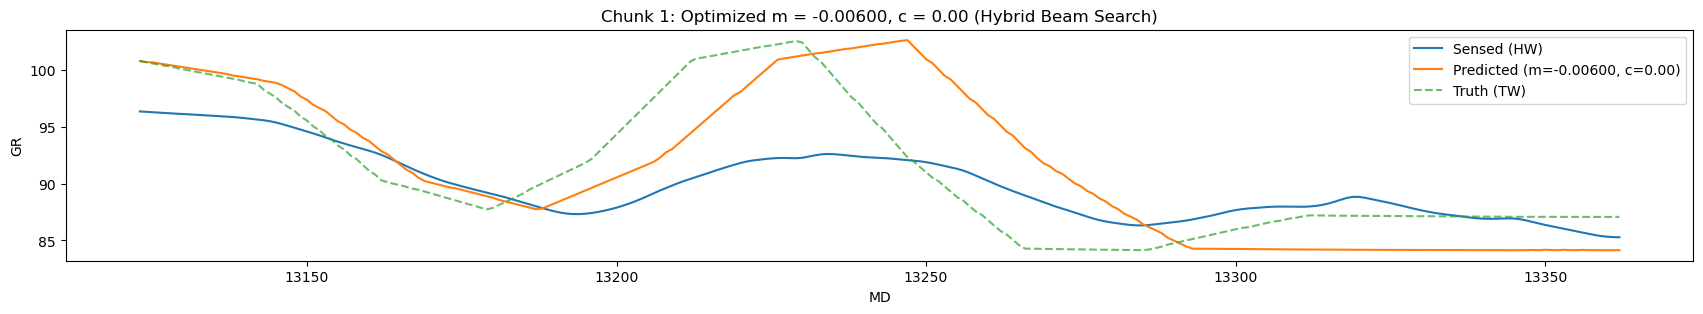

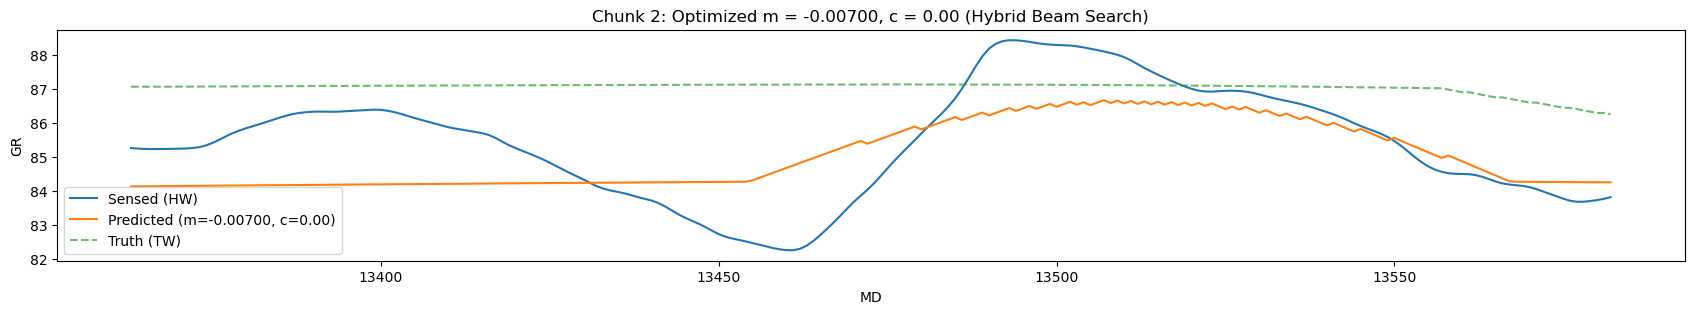

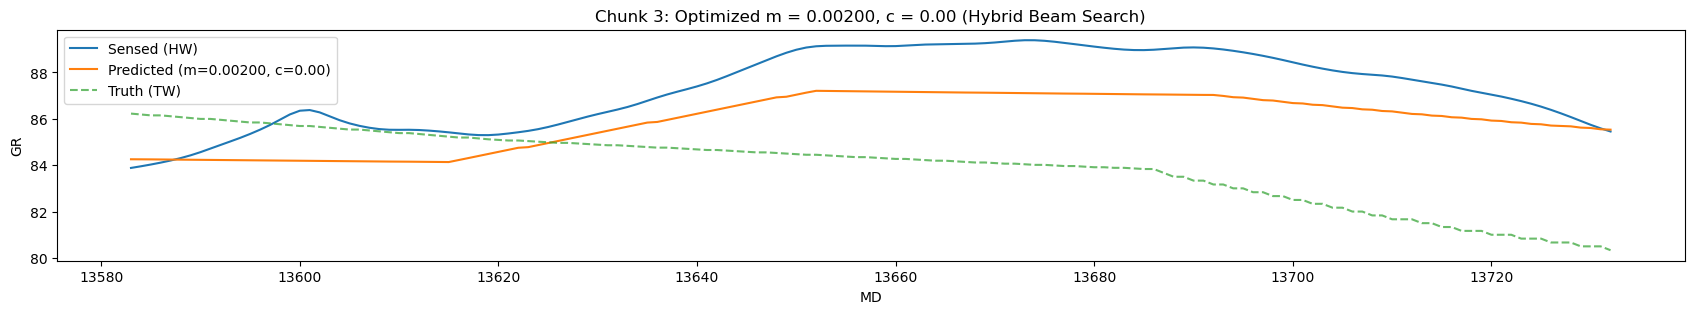

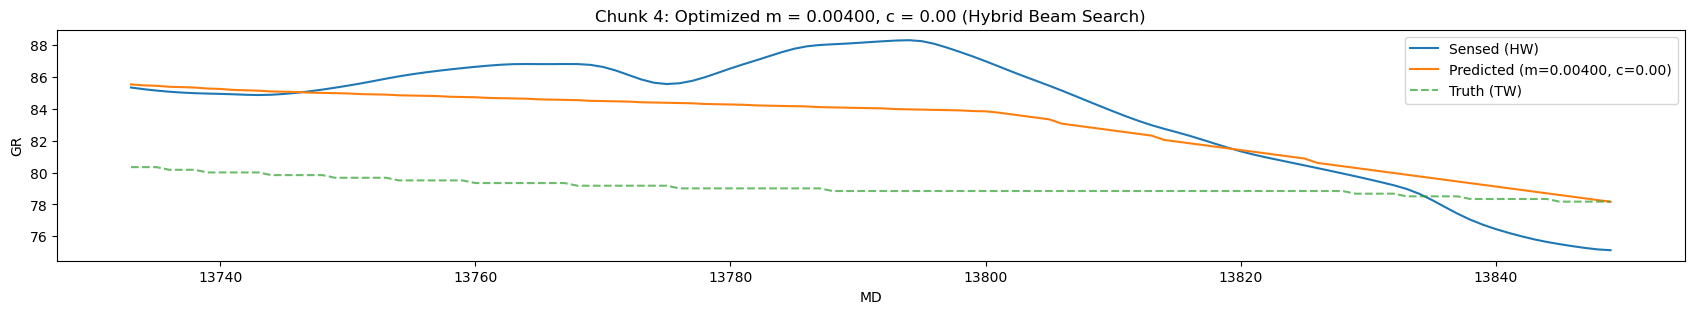

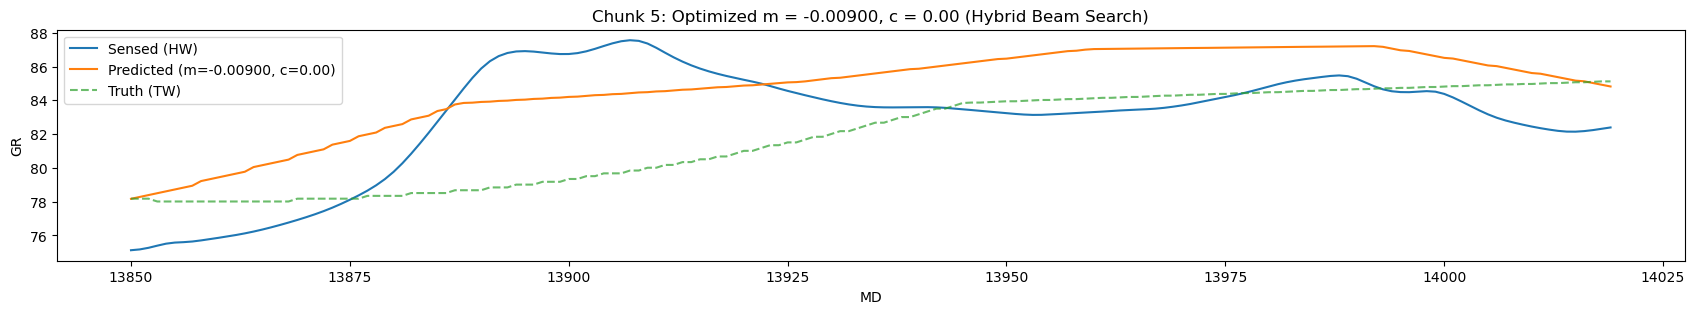

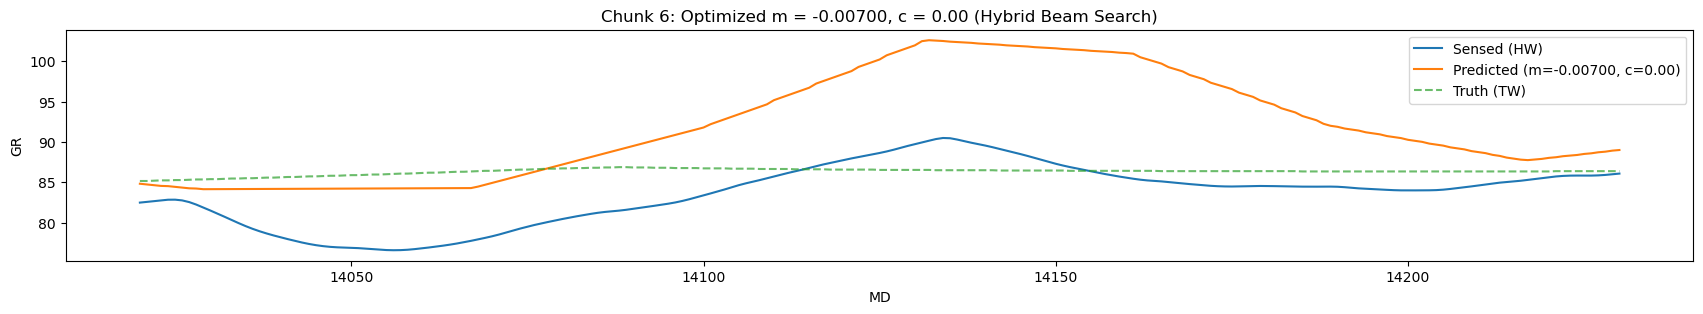

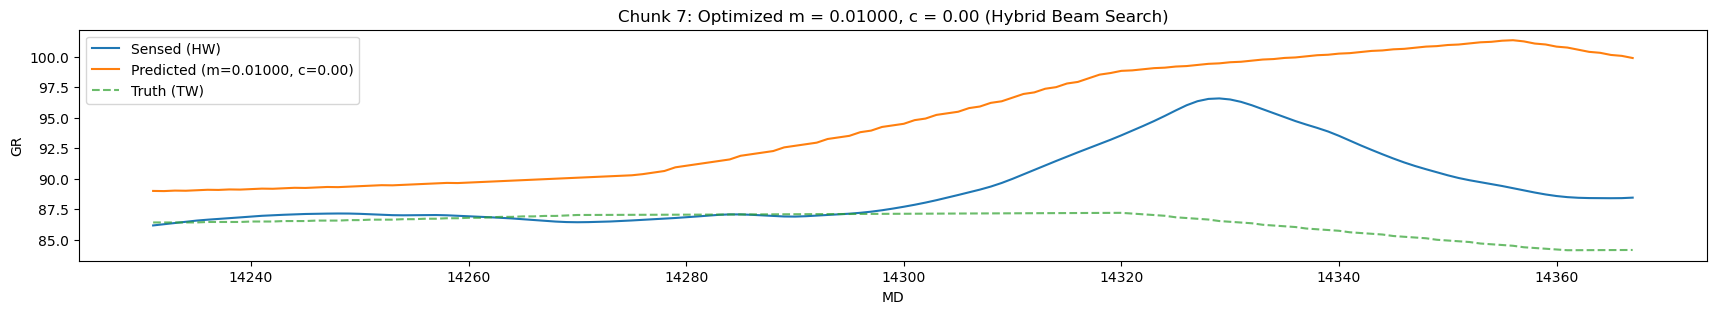

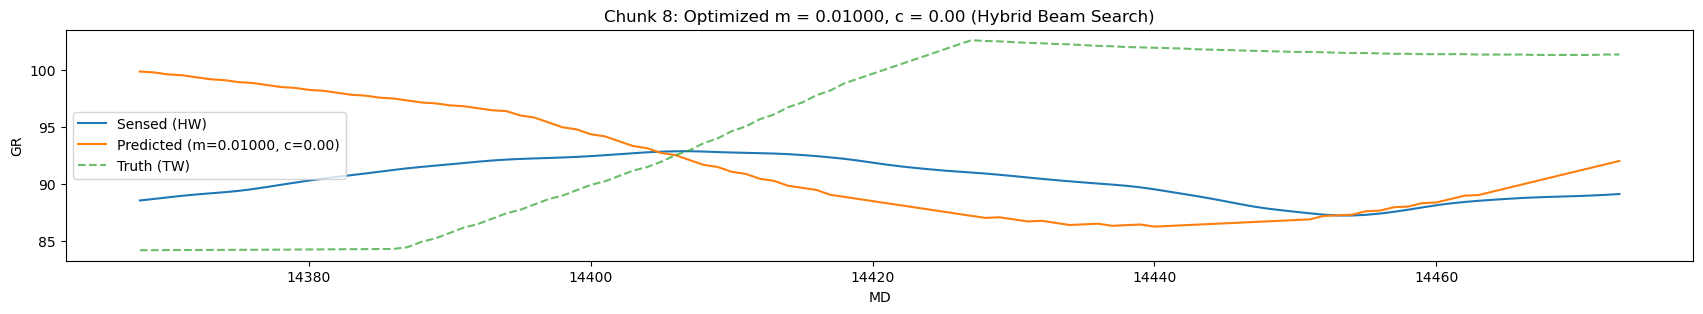

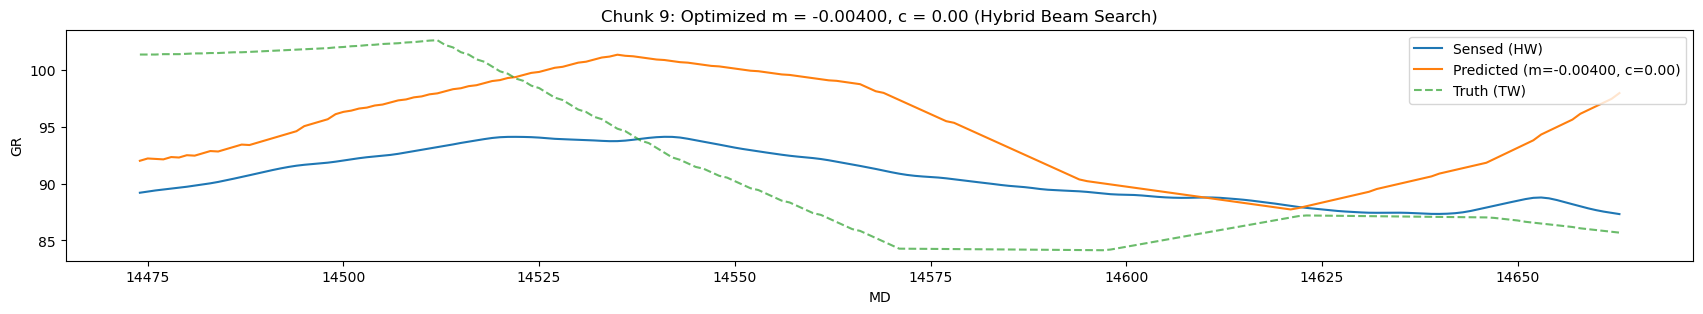

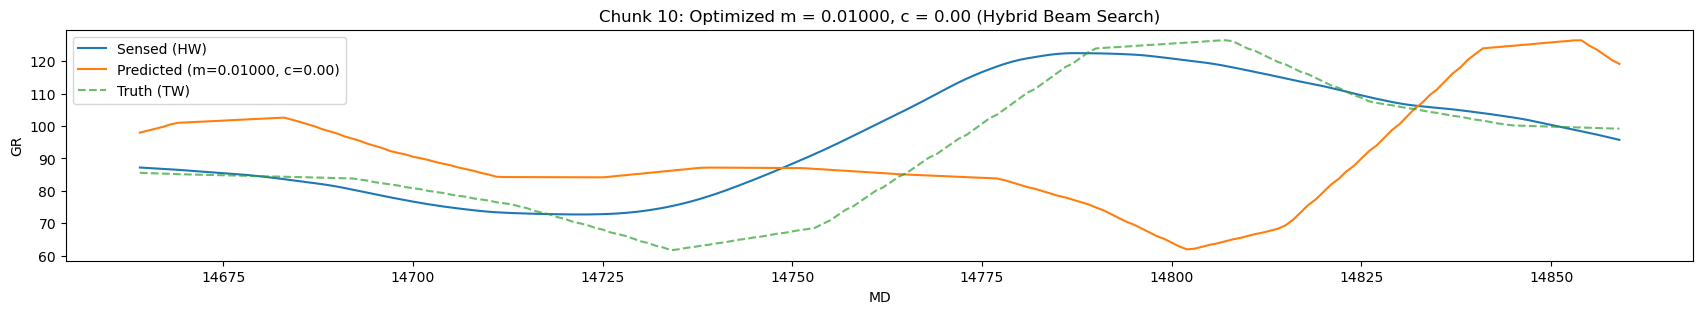

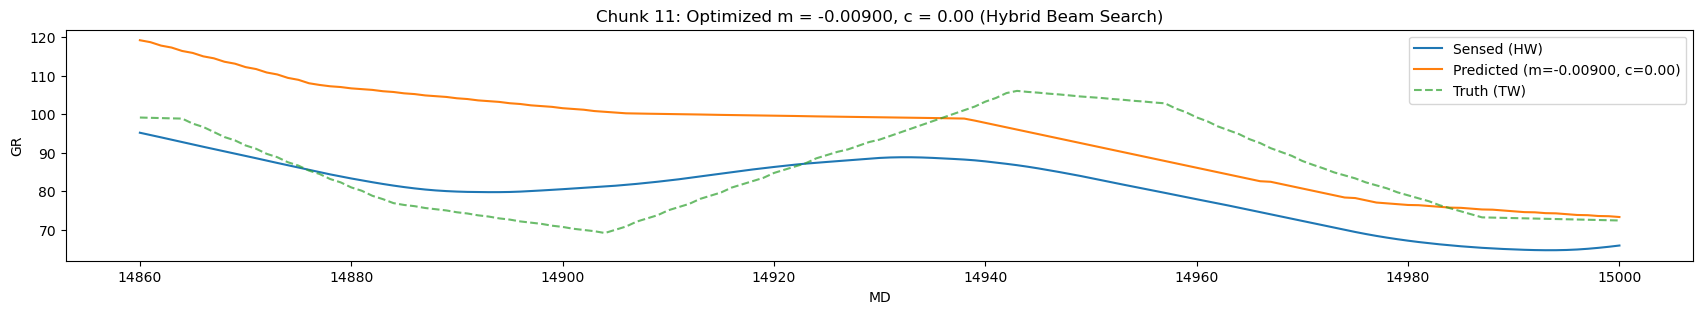

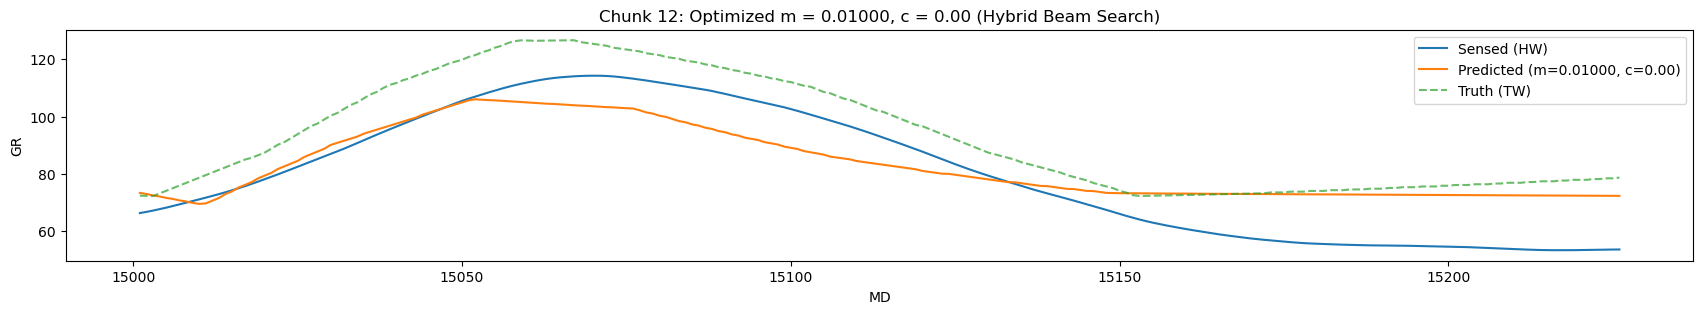

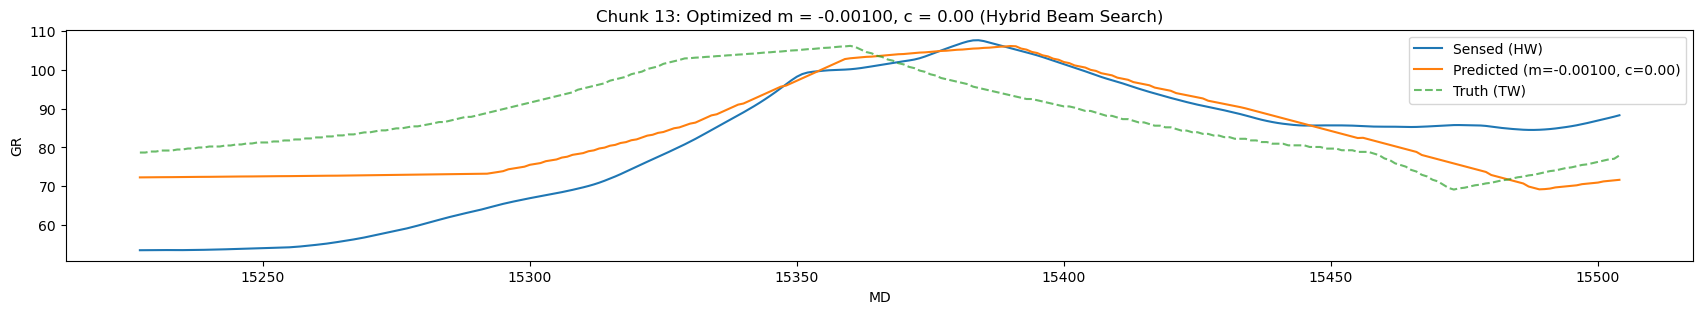

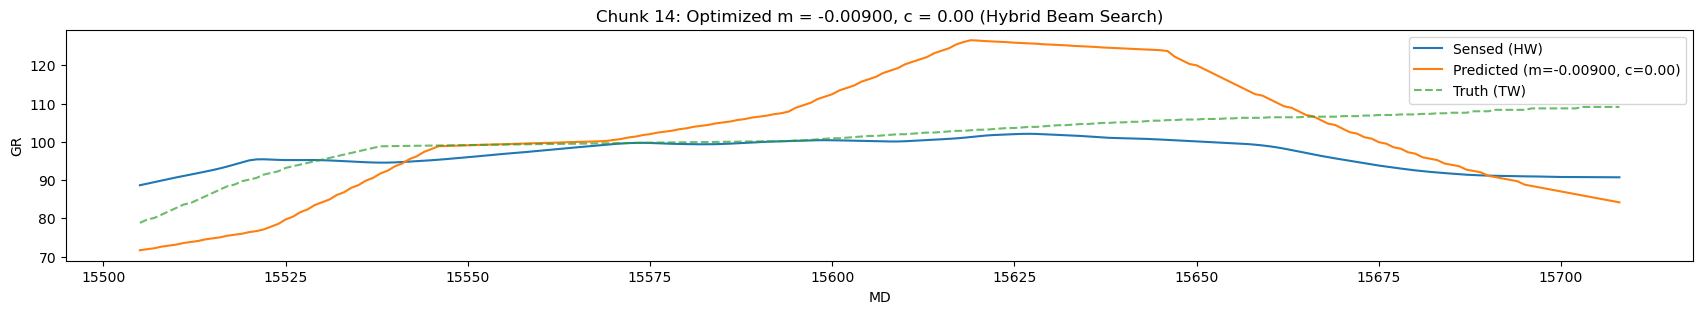

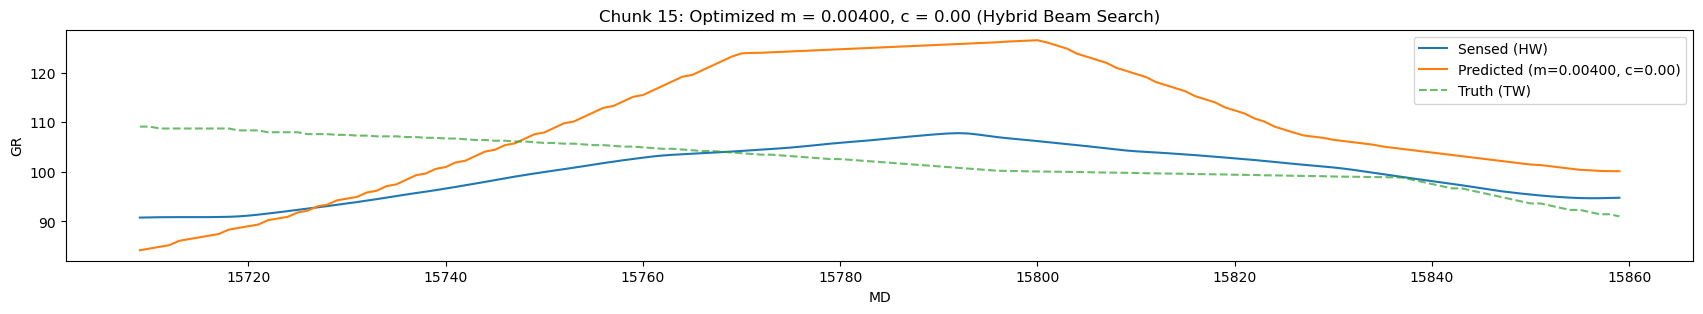

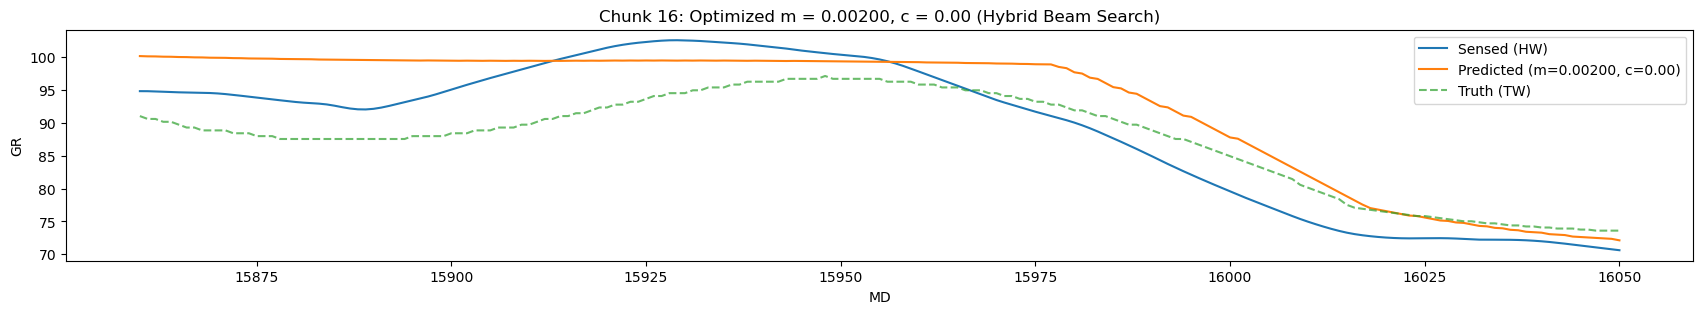

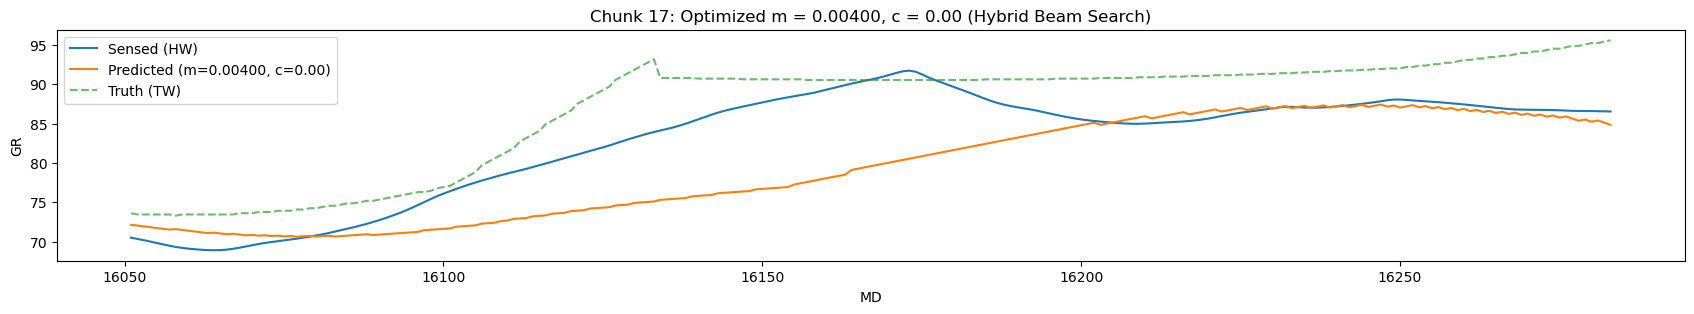

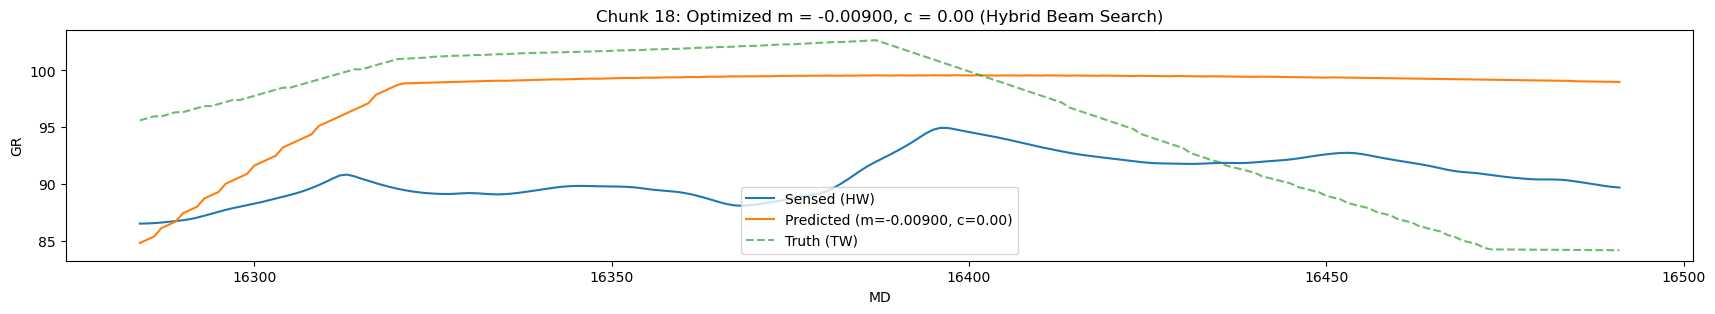

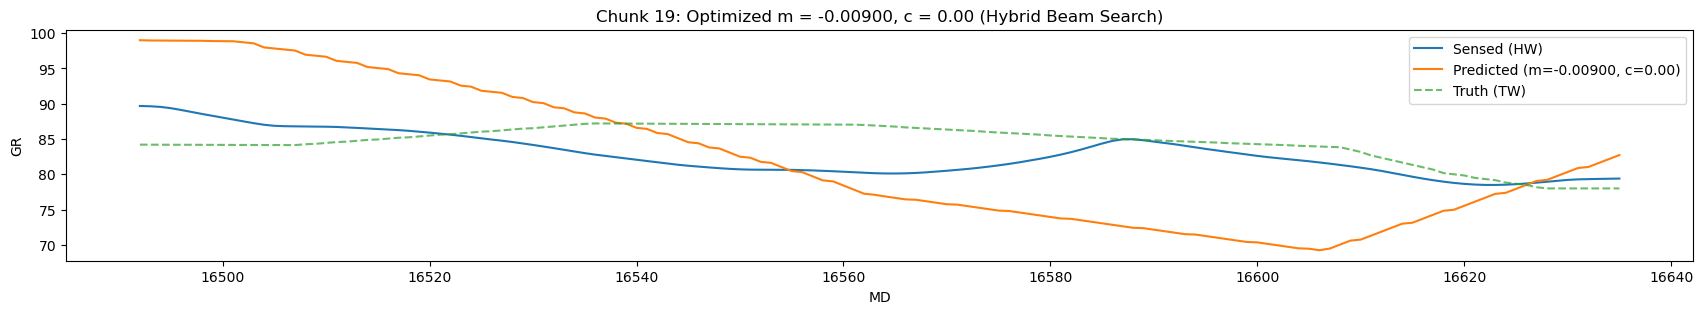

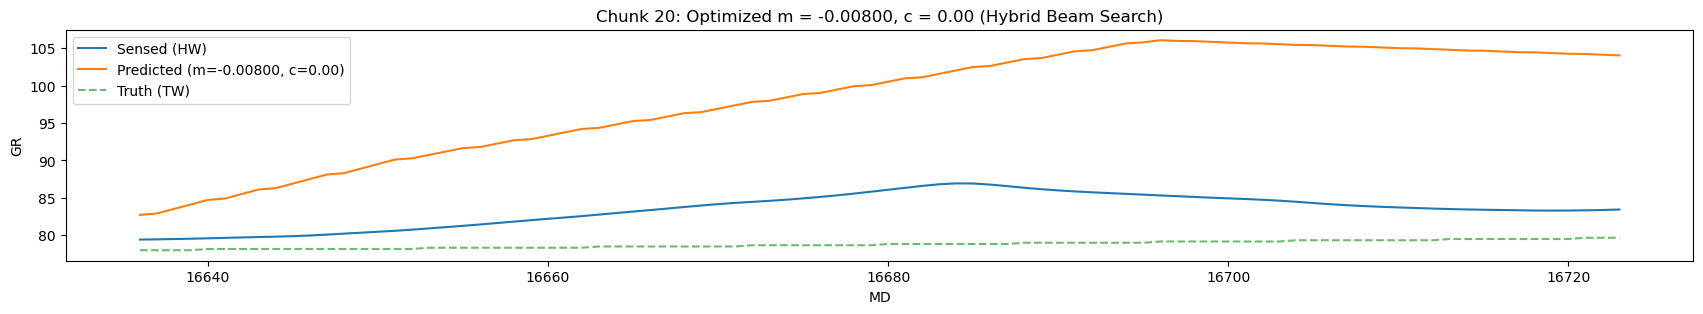

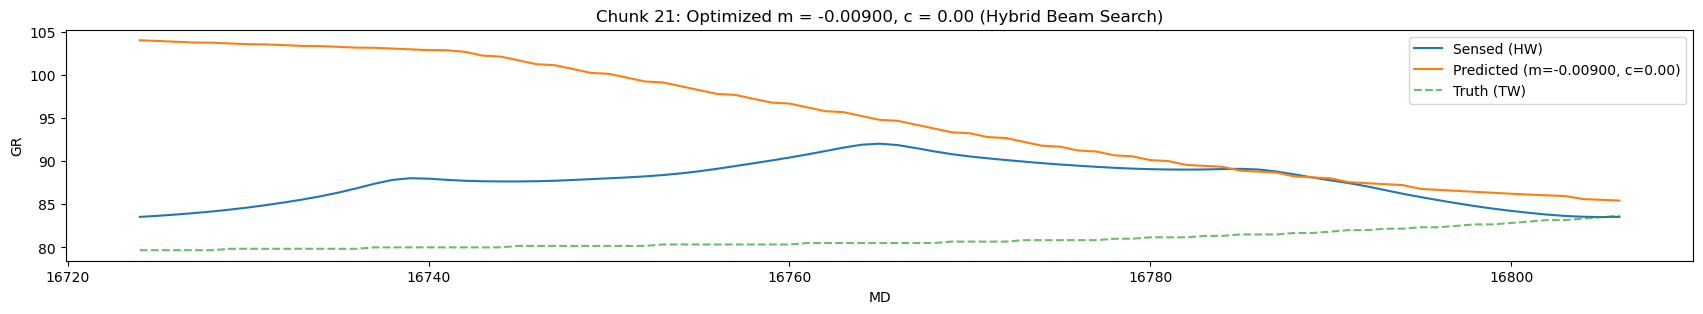

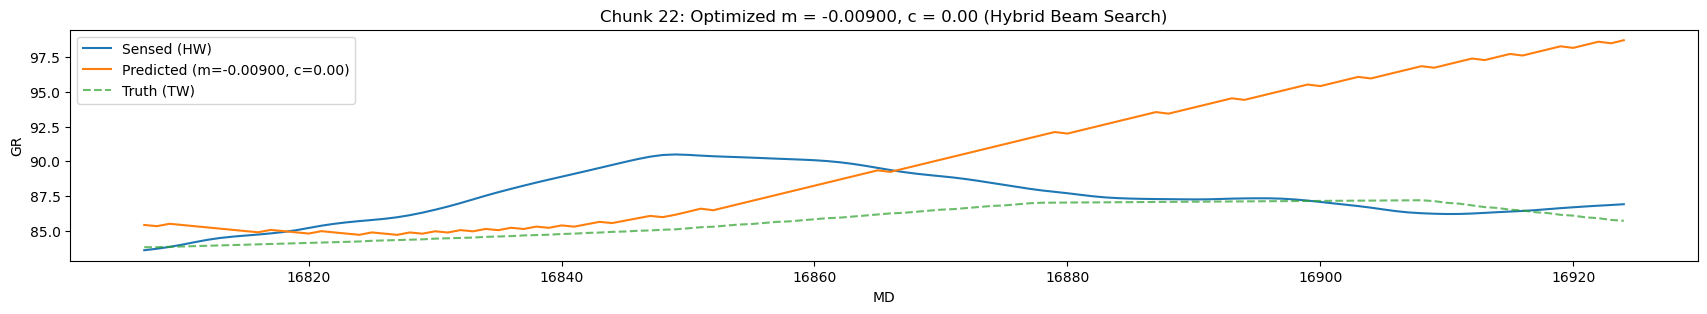

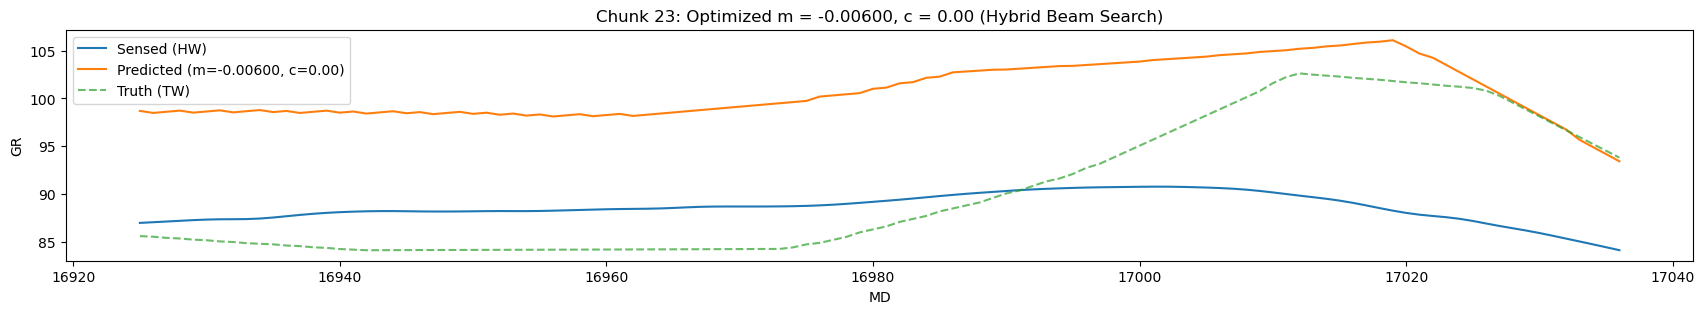

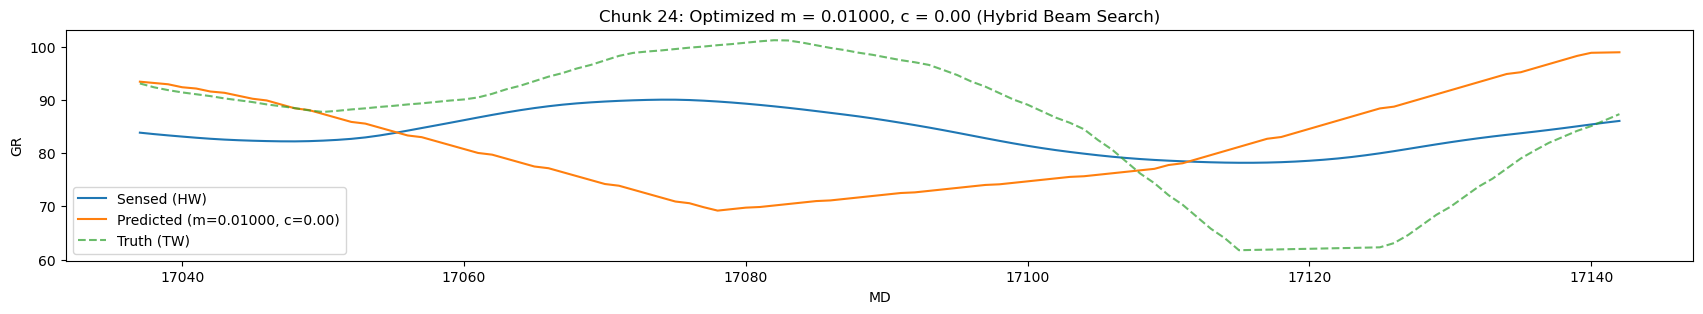

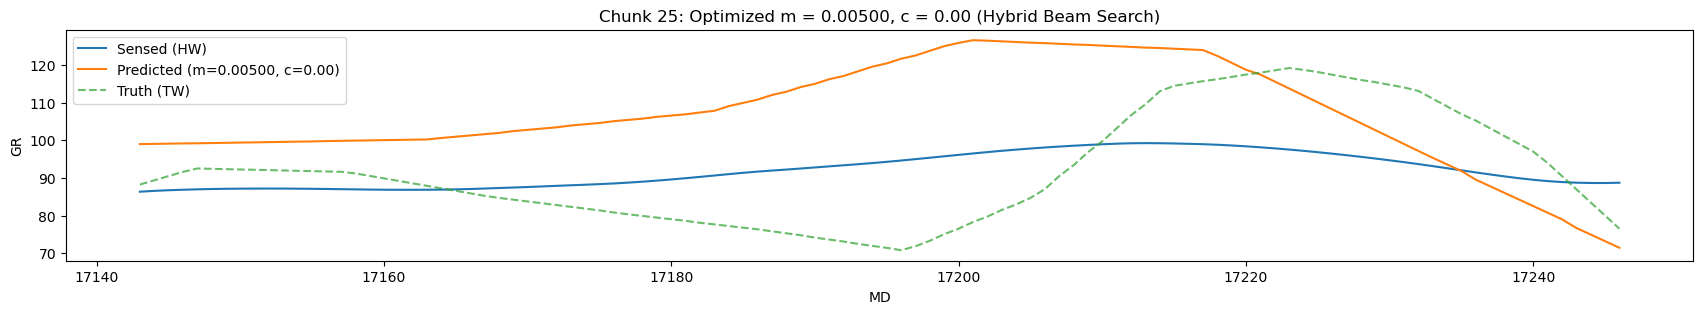

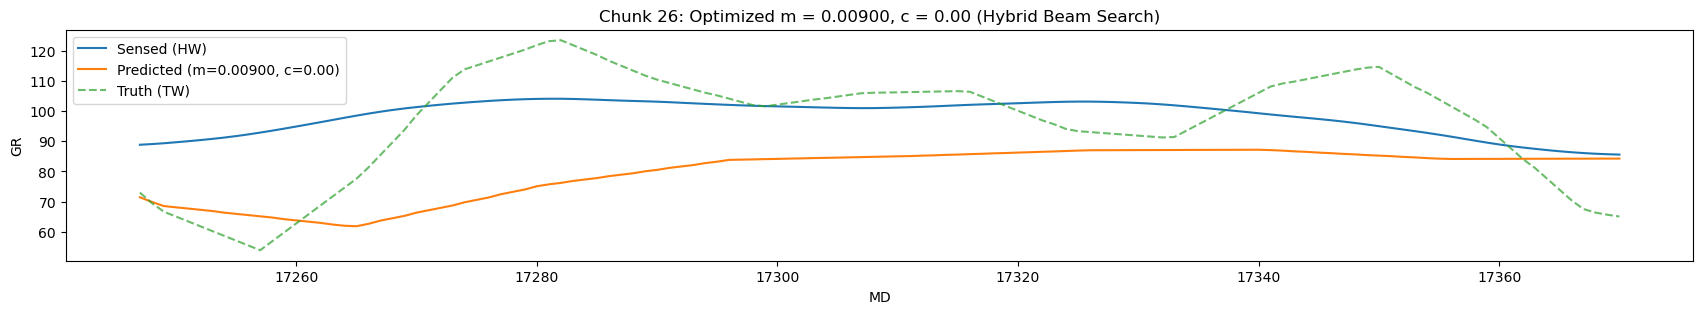

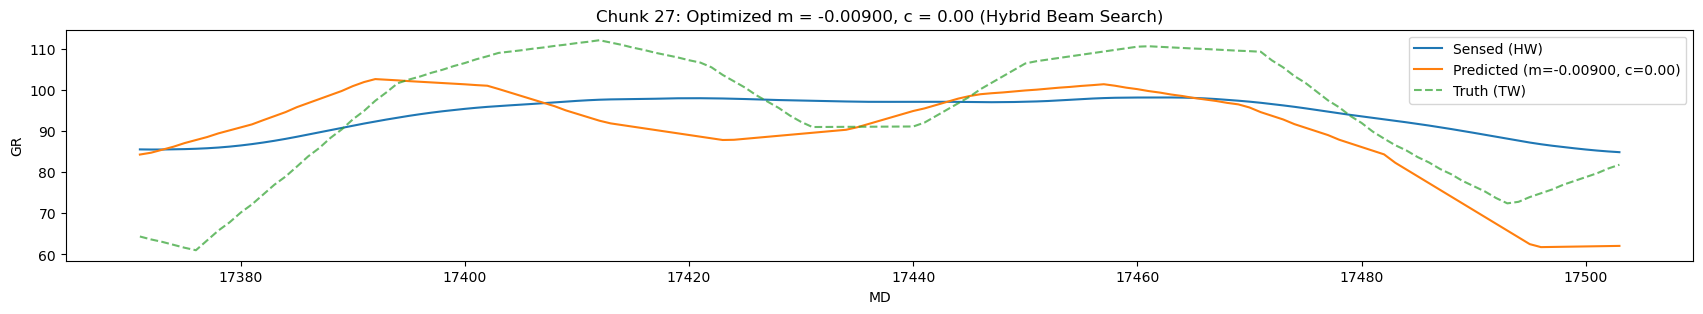

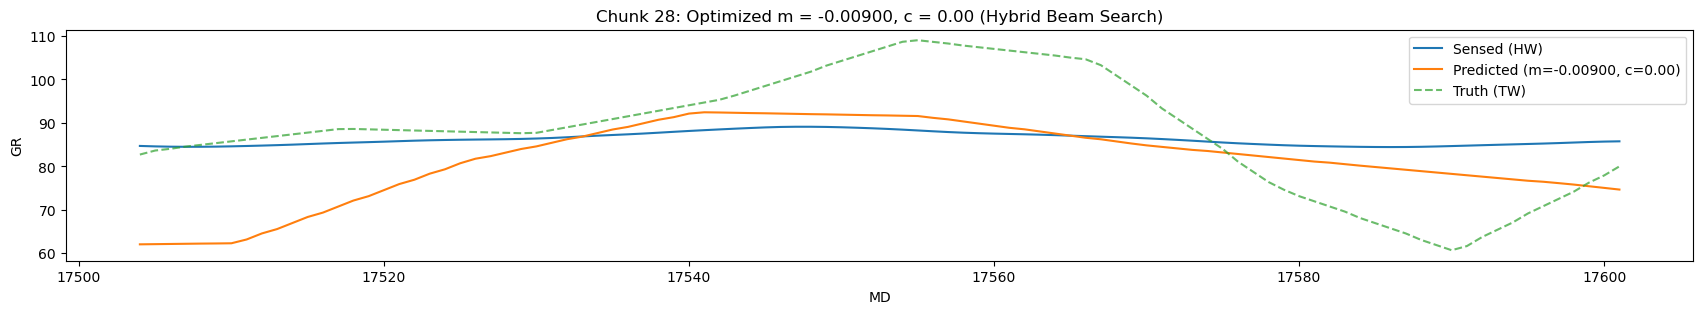

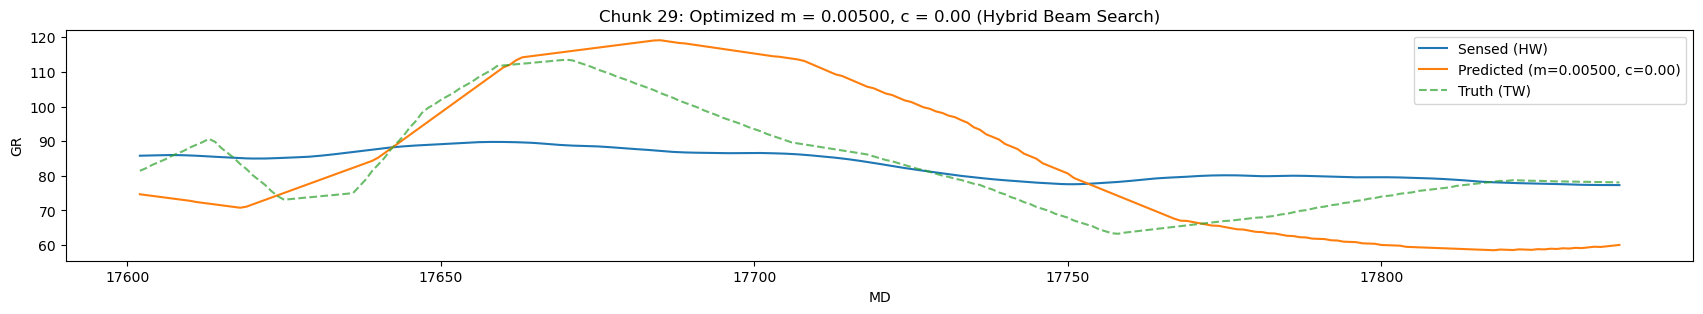

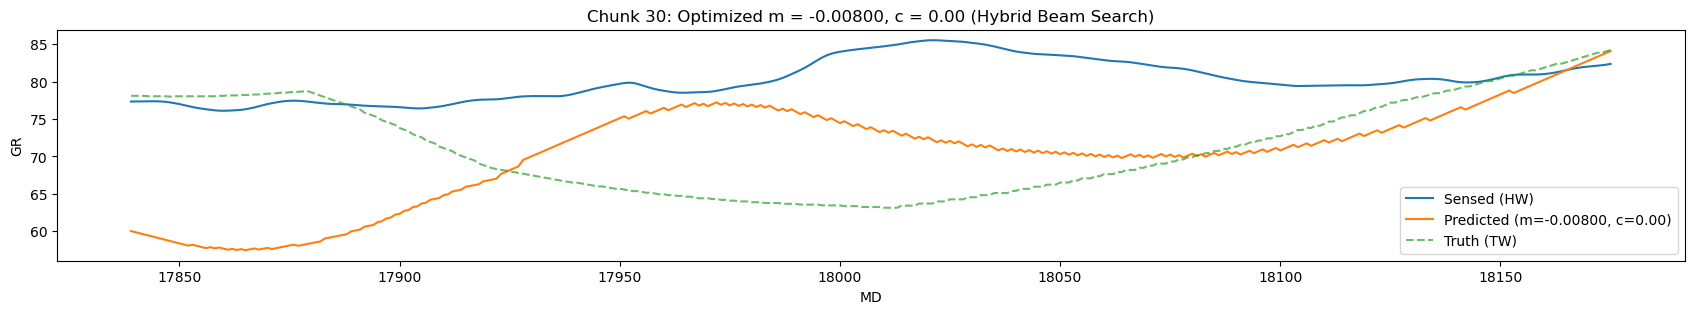

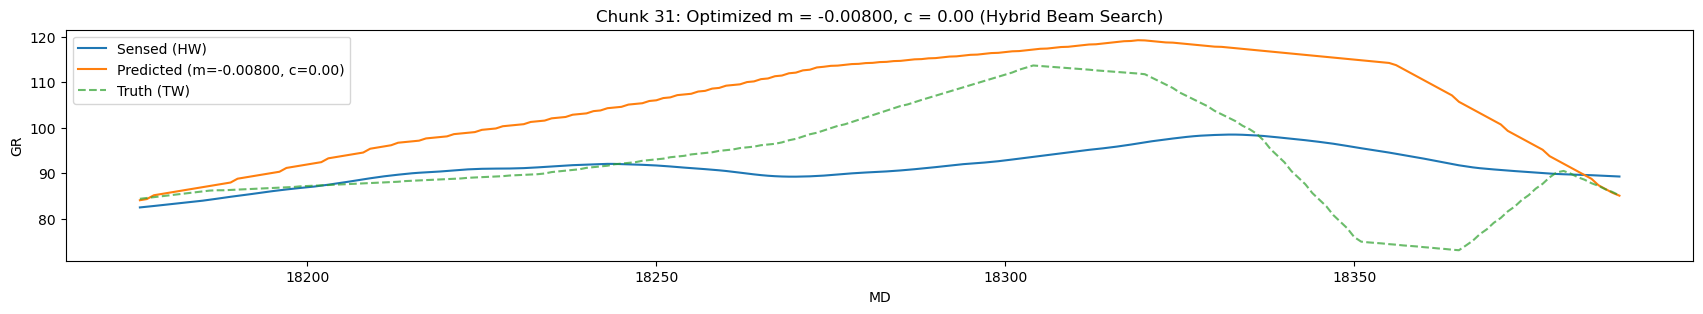

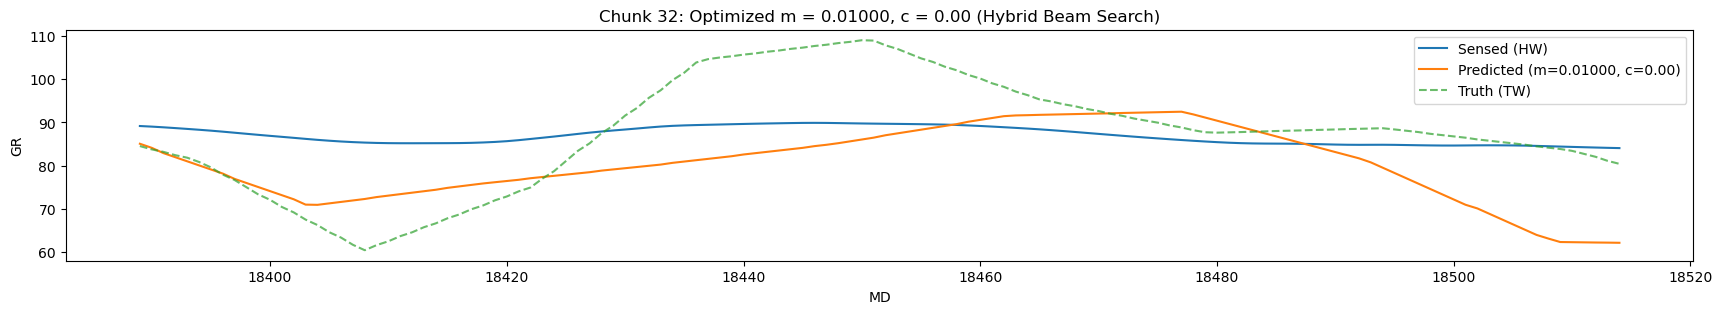

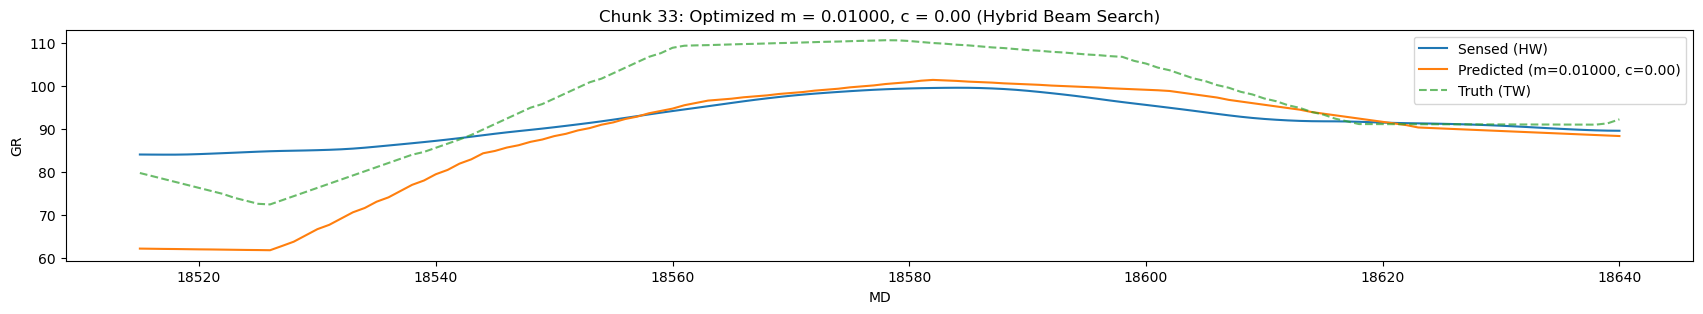

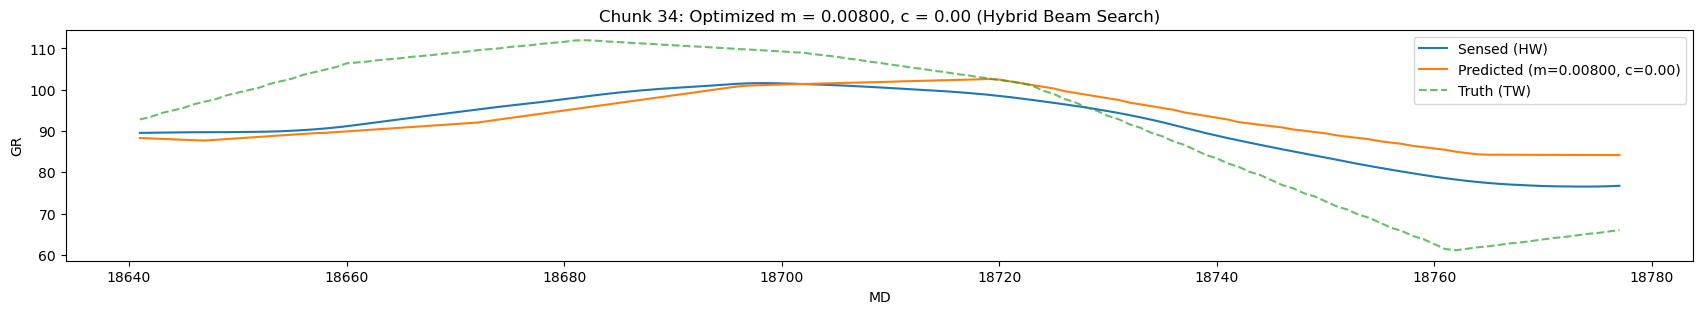

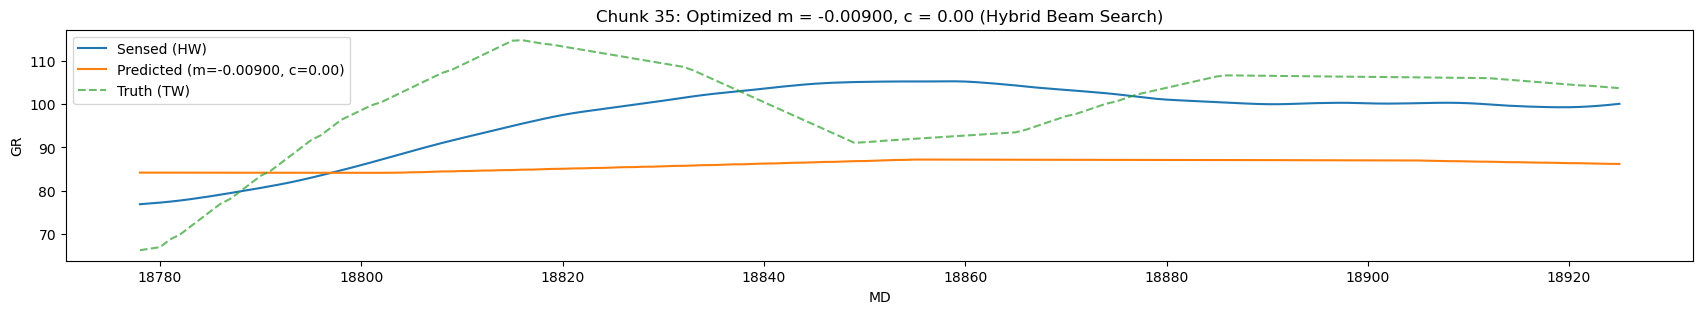

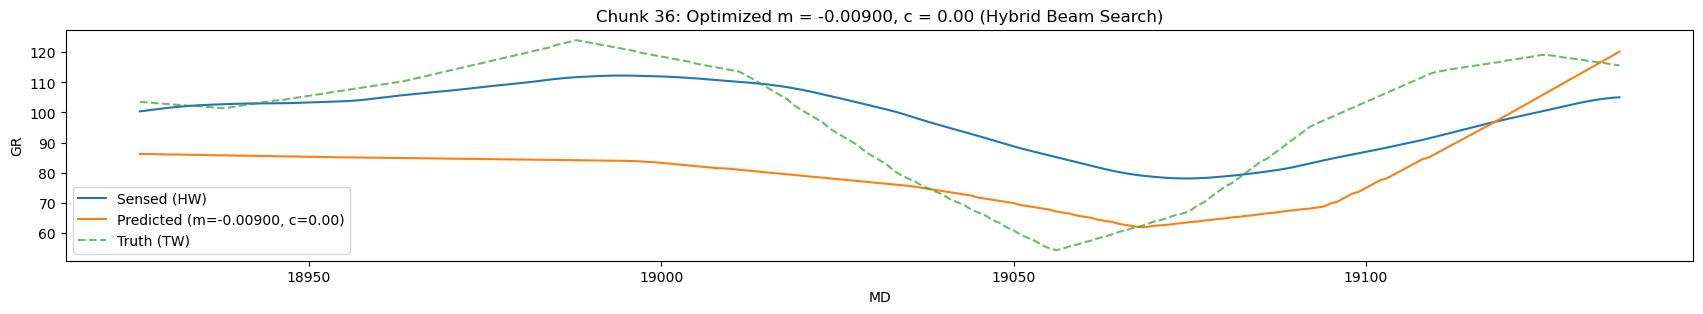

In [19]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, butter, filtfilt
import warnings
warnings.filterwarnings('ignore')

# --- 1. DATA PREPARATION ---
IS_KAGGLE = os.path.exists('/kaggle/input')
BASE_DIR = '/kaggle/input/competitions/rogii-wellbore-geology-prediction' if IS_KAGGLE else '../data'
train_data = os.path.join(BASE_DIR, "train")
well = '00bbac68' 

def remove_rotation_noise(gr_series, cutoff):
    gr_filled = gr_series.interpolate(method='linear').bfill().ffill()
    nyquist = 0.5 
    normal_cutoff = cutoff / nyquist
    b, a = butter(1, normal_cutoff, btype='low', analog=False)
    return filtfilt(b, a, gr_filled)

hw = pd.read_csv(os.path.join(train_data, f"{well}__horizontal_well.csv"))
tw = pd.read_csv(os.path.join(train_data, f"{well}__typewell.csv"))

mask = hw['TVT_input'].isna()
evalz = hw[mask].copy()
# Removed the > 17000 filter to run on the whole well

slope, intercept = np.polyfit(evalz['MD'], evalz['Z'], deg=1)
pred = evalz['Z'] - evalz['MD'] * slope - intercept
pred_norm = pred - pred.iloc[0] 
tvt_norm = -evalz['TVT'] + evalz['TVT'].iloc[0]

evalz['norm_TVT'] = tvt_norm
evalz['norm_Z'] = pred_norm
evalz['Z-bl'] = evalz['norm_TVT'] - evalz['norm_Z']
evalz['GR'] = remove_rotation_noise(evalz['GR'], cutoff=0.009)

# Chunk Generation via Prominent Peaks
x = evalz['MD'].copy().reset_index(drop=True)
y = evalz['GR'].copy().reset_index(drop=True)
peaks, _ = find_peaks(y, prominence=3.0, distance=50)
midpoints = (peaks[:-1] + peaks[1:]) // 2
boundaries = [0] + midpoints.tolist() + [len(y)]

chunks = [evalz.iloc[boundaries[i]:boundaries[i+1]] for i in range(len(boundaries)-1)]

# --- 2. VECTORIZED BEAM SEARCH (HYBRID CORRELATION + RMSE) ---
# ms = np.array([0.07, 0.06, 0.05, 0.04, 0.03, 0.02, 0.01, 0, -0.01, -0.02, -0.03, -0.04, -0.05, -0.06, -0.07])
ms = np.array([0.009, 0.008, 0.007, 0.006, 0.005, 0.004, 0.003, 0.002, 0.010, 0, -0.001, -0.002, -0.003, -0.004, -0.005, -0.006, -0.007, -0.008, -0.009])
# cs = np.array([-0.2, -0.1, 0, 0.1, 0.2])
cs = np.array([0])

# Create a flattened grid of every (m, c) combination
M_grid, C_grid = np.meshgrid(ms, cs, indexing='ij')
M_flat = M_grid.ravel()
C_flat = C_grid.ravel()

initial_tvt_0 = evalz['TVT'].iloc[0]
beam_width = 30 

tw_tvt_vals = tw['TVT'].values
tw_gr_vals = tw['GR'].values

beams = [{
    "tvt_0": initial_tvt_0,
    "m_path": [],
    "c_path": [],
    "total_error": 0.0,
    "tvt_cands": [],
    "gr_cands": []
}]

print("Executing Vectorized 2D Grid Beam Search with Hybrid Metric...")

for i, chunk in enumerate(chunks):
    md_arr = chunk['MD'].values
    gr_arr = chunk['GR'].values
    md_0 = md_arr[0]
    
    # Pre-calculate the Z-shift and MD-differences for the whole chunk
    norm_z_shift = chunk['norm_Z'].values - chunk['norm_Z'].iloc[0]
    md_diff = md_arr - md_0
    
    new_beams = []
    
    for beam in beams:
        # 1. VECTORIZED TVT CALCULATION (Combines M_flat and C_flat)
        tvt_matrix = M_flat[:, None] * md_diff - norm_z_shift + beam["tvt_0"] + C_flat[:, None]
        
        # 2. VECTORIZED INTERPOLATION
        gr_pred_matrix = np.interp(
            tvt_matrix.ravel(), 
            tw_tvt_vals, 
            tw_gr_vals, 
            left=np.nan, 
            right=np.nan
        ).reshape(tvt_matrix.shape)
        
        # 3. FAST HYBRID CALCULATION FOR EACH CANDIDATE
        # Calculate MSE to ground the vertical distance
        sq_errors = (gr_pred_matrix - gr_arr)**2
        mses = np.nanmean(sq_errors, axis=1)
        
        chunk_costs = np.zeros(gr_pred_matrix.shape[0])
        for j in range(gr_pred_matrix.shape[0]):
            valid_mask = ~np.isnan(gr_pred_matrix[j]) & ~np.isnan(gr_arr)
            if np.sum(valid_mask) > 5:
                x_vals = gr_pred_matrix[j, valid_mask]
                y_vals = gr_arr[valid_mask]
                
                if np.std(x_vals) > 1e-5 and np.std(y_vals) > 1e-5:
                    c_val = np.corrcoef(x_vals, y_vals)[0, 1]
                    
                    # THE HYBRID COST
                    # Combines the Shape-Matching of Correlation with the Vertical-Grounding of MSE
                    chunk_costs[j] = ((1.0 - c_val) * 1000) + mses[j]
                else:
                    # If the segment is completely flat, rely on MSE only
                    chunk_costs[j] = mses[j] if not np.isnan(mses[j]) else 1e6
            else:
                chunk_costs[j] = 1e6
        
        # 4. BRANCH CREATION
        for j in range(len(M_flat)):
            new_beams.append({
                "tvt_0": tvt_matrix[j, -1],
                "m_path": beam["m_path"] + [M_flat[j]],
                "c_path": beam["c_path"] + [C_flat[j]],
                "total_error": beam["total_error"] + chunk_costs[j],
                "tvt_cands": beam["tvt_cands"] + [pd.Series(tvt_matrix[j], index=chunk.index)],
                "gr_cands": beam["gr_cands"] + [pd.Series(gr_pred_matrix[j], index=chunk.index)]
            })
            
    # Sort and prune beams to strictly enforce beam width
    new_beams.sort(key=lambda x: x["total_error"])
    beams = new_beams[:beam_width]

# --- 3. EXTRACT RESULTS AND PLOT ---
best_overall_path = beams[0]
best_m_sequence = best_overall_path["m_path"]
best_c_sequence = best_overall_path["c_path"]
best_gr_sequence = best_overall_path["gr_cands"]
best_tvt_sequence = best_overall_path["tvt_cands"]

# Calculate Overall RMSE against the evalz ground truth
final_tvt = pd.concat(best_tvt_sequence)
final_rmse = np.sqrt(np.nanmean((final_tvt - evalz['TVT'])**2))
print(f"Overall RMSE between Final Concatenated TVT and evalz['TVT']: {final_rmse:.6f}")

# Plot the individual chunks
for i, chunk in enumerate(chunks):
    plt.figure(figsize=(21, 3))
    
    best_m = best_m_sequence[i]
    best_c = best_c_sequence[i]
    best_pred_gr = best_gr_sequence[i]
    
    plt.plot(chunk['MD'], chunk['GR'], label='Sensed (HW)')
    plt.plot(chunk['MD'], best_pred_gr, label=f"Predicted (m={best_m:.5f}, c={best_c:.2f})")
    
    truth_gr = np.interp(chunk['TVT'], tw['TVT'], tw['GR']) 
    plt.plot(chunk['MD'], truth_gr, label="Truth (TW)", linestyle='--', alpha=0.7)
    
    plt.title(f"Chunk {i+1}: Optimized m = {best_m:.5f}, c = {best_c:.2f} (Hybrid Beam Search)")
    plt.xlabel("MD")
    plt.ylabel("GR")
    plt.legend()

plt.show()

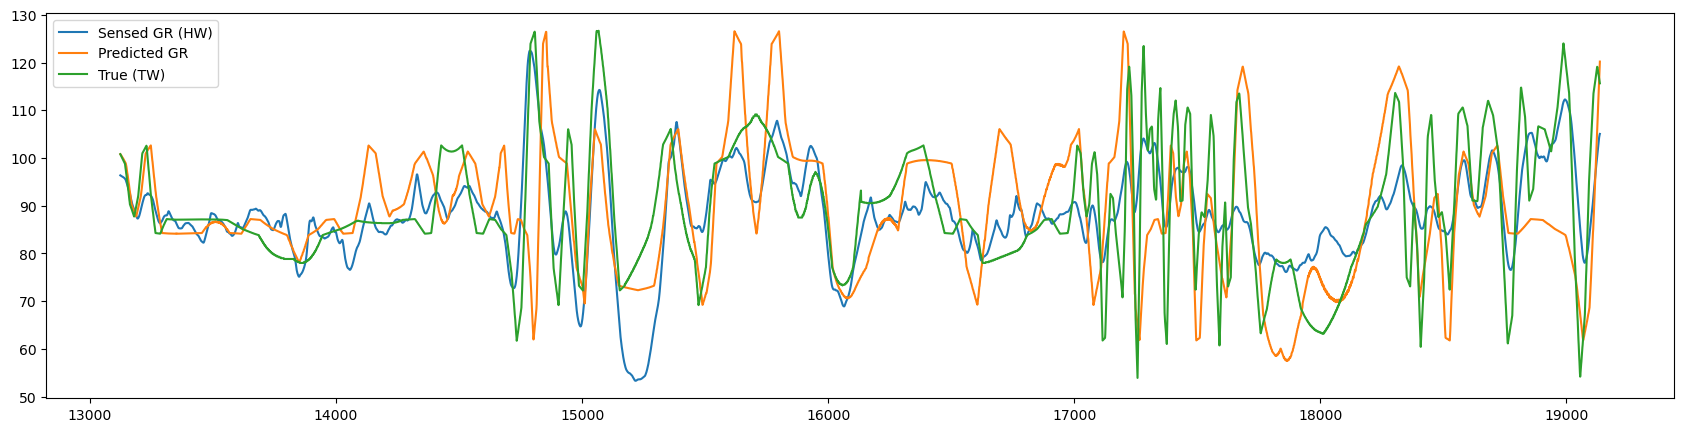

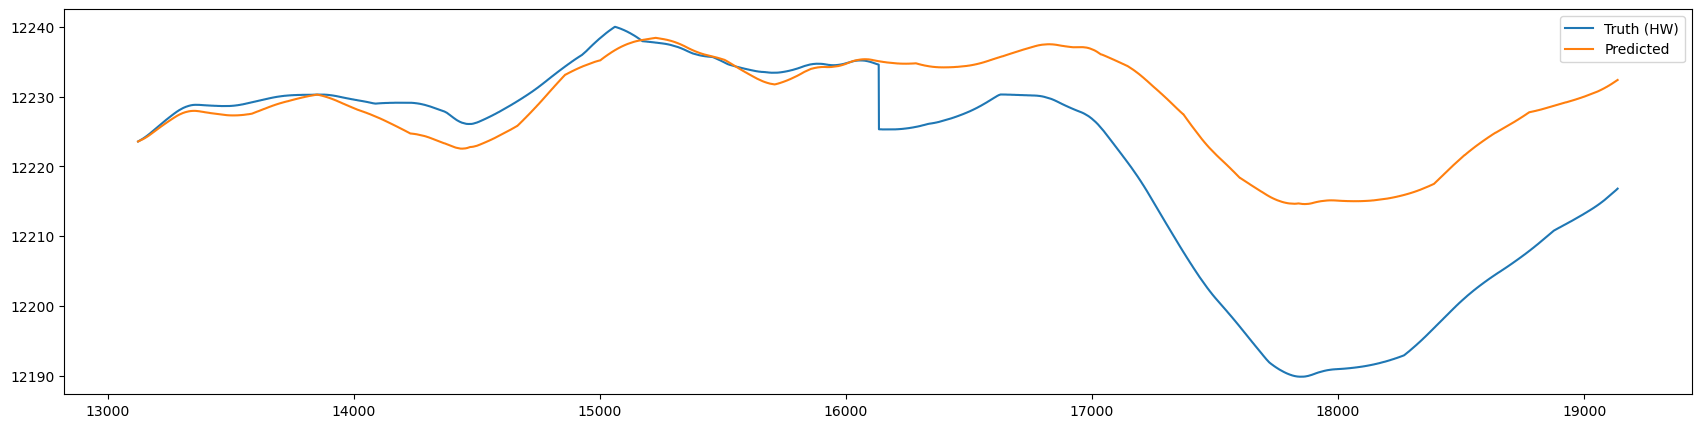

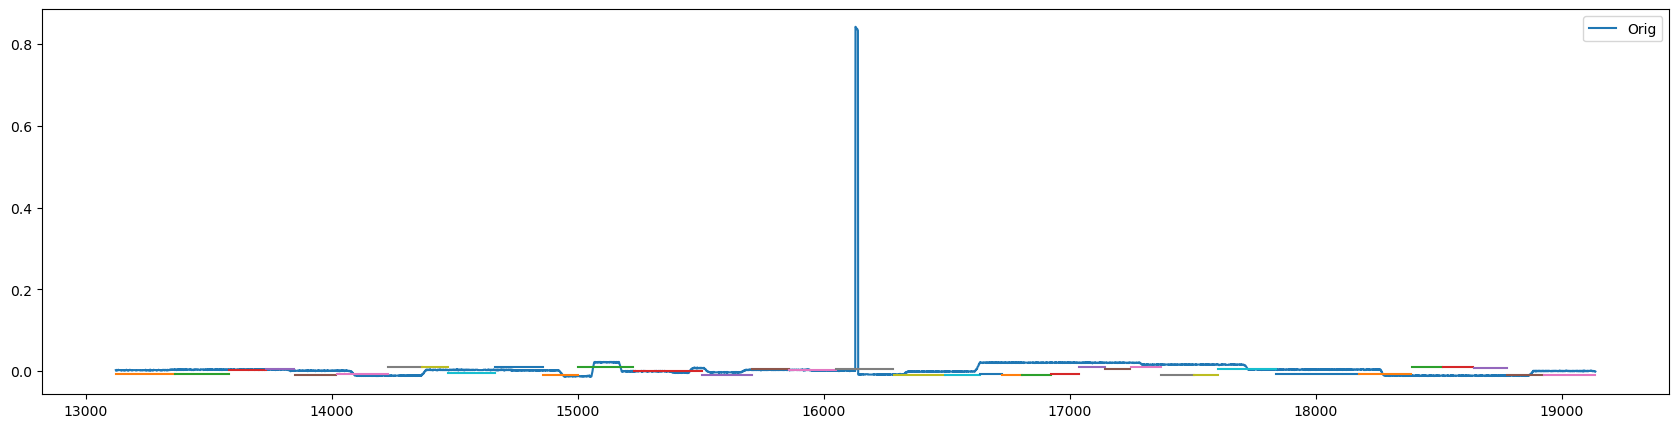

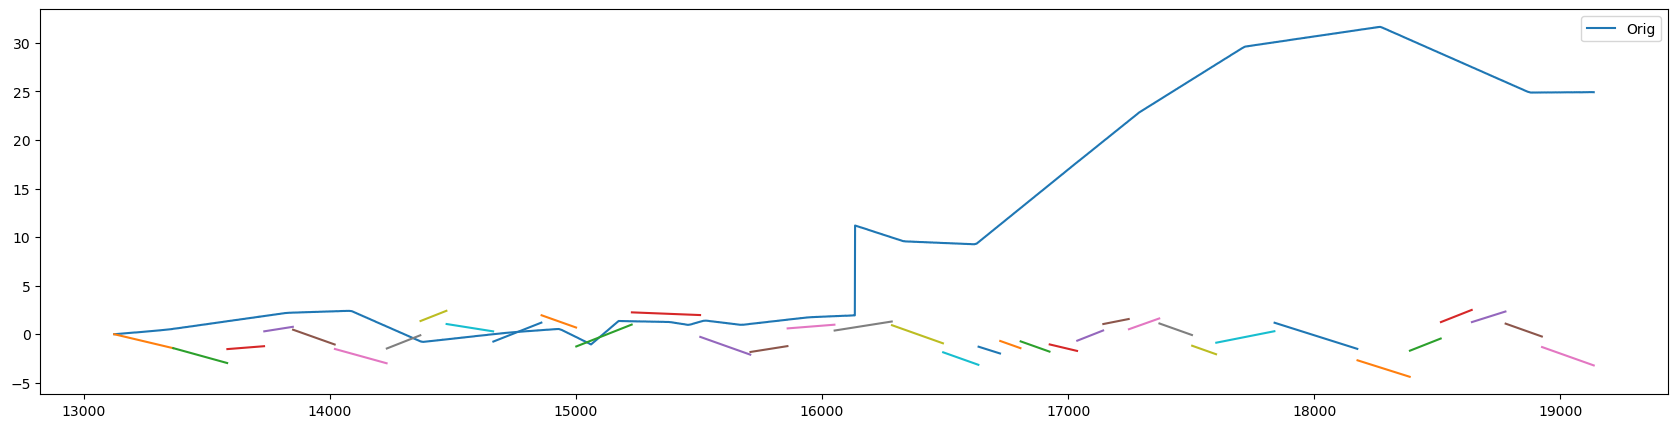

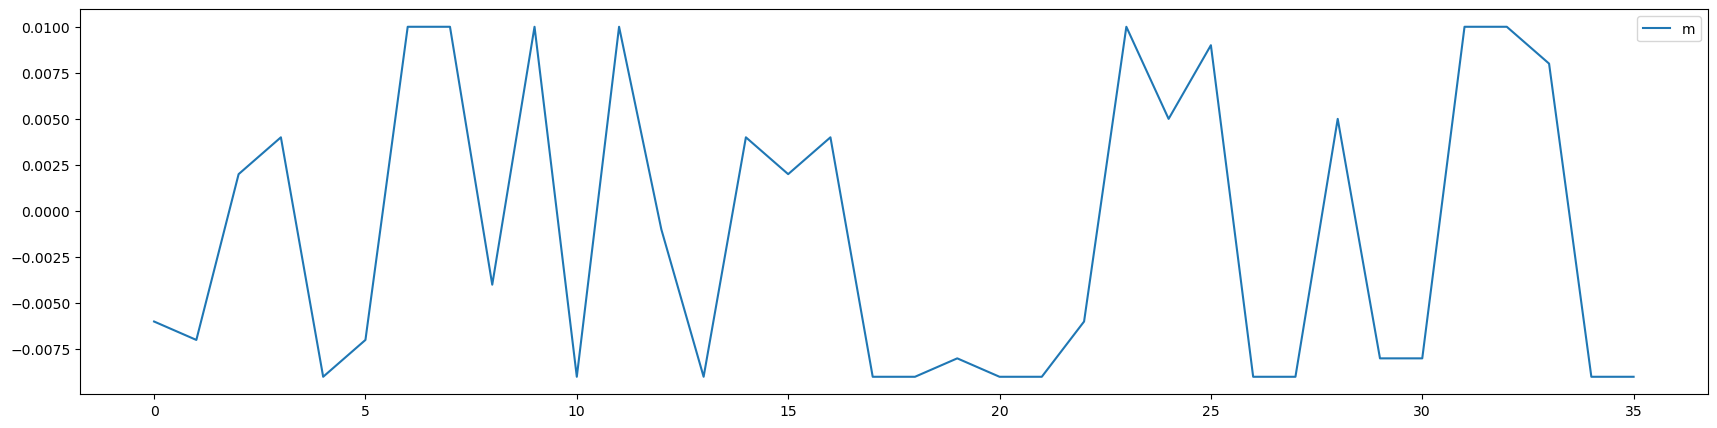

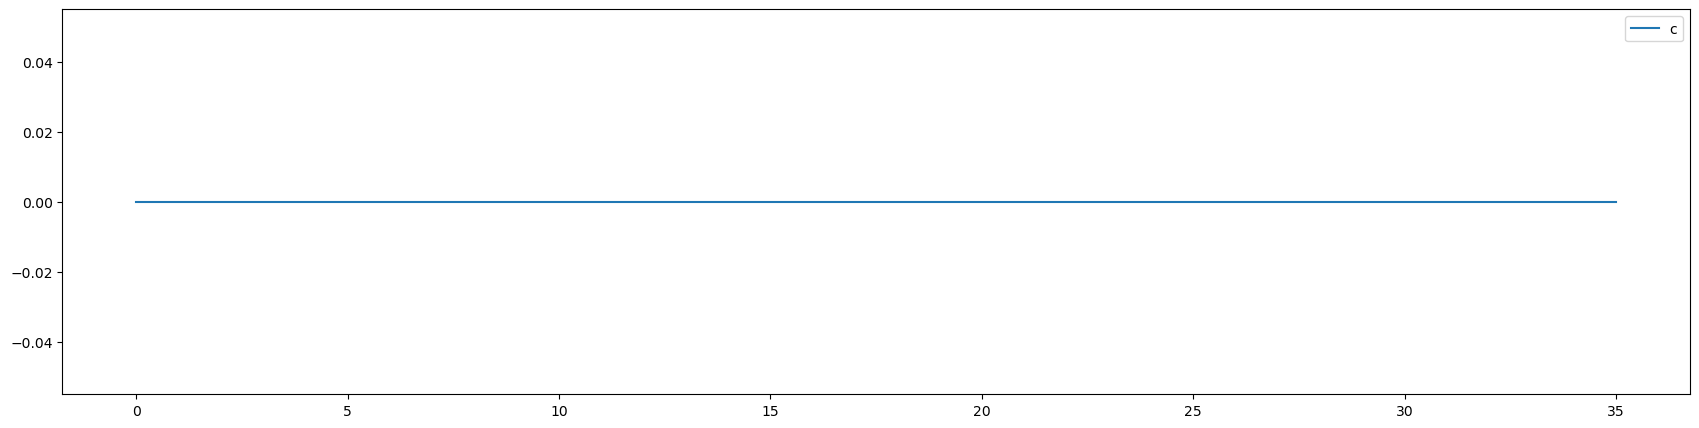

In [20]:
plt.figure(figsize=(21, 5))
gr = np.concat(best_gr_sequence)
plt.plot(evalz['MD'], evalz['GR'], label='Sensed GR (HW)')
plt.plot(evalz['MD'], gr, label='Predicted GR')
gr = np.interp(evalz['TVT'], tw['TVT'], tw['GR'])
plt.plot(evalz['MD'], gr, label='True (TW)')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['TVT'], label='Truth (HW)')
plt.plot(evalz['MD'], final_tvt, label='Predicted')
plt.legend()
# plt.plot(evalz['MD'], -evalz['TVT'] + 2 * evalz['TVT'].iloc[0])

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], d(evalz['Z-bl']), label='Orig')
for i, chunk in enumerate(chunks):
    repeat_count = boundaries[i + 1] - boundaries[i]
    plt.plot(chunk['MD'], [best_m_sequence[i]] * repeat_count)
# ms = []
# for i in range(len(boundaries) - 1):
#     ms.extend()
# plt.plot(evalz['MD'], ms, label='Pred')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(evalz['MD'], evalz['Z-bl'], label='Orig')
o = 0
for i, chunk in enumerate(chunks):
    z = (chunk['MD'] - chunk['MD'].iloc[0]) * best_m_sequence[i] + best_c_sequence[i]
    plt.plot(chunk['MD'], z + o)
    o = z.iloc[-1]
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(best_m_sequence, label='m')
plt.legend()

plt.figure(figsize=(21, 5))
plt.plot(best_c_sequence, label='c')
plt.legend()

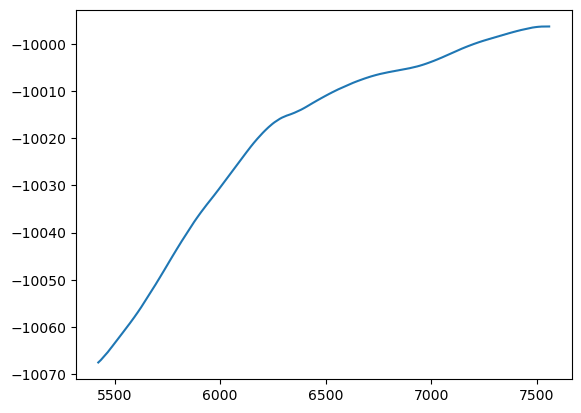

In [860]:
plt.plot(evalz['Z'])

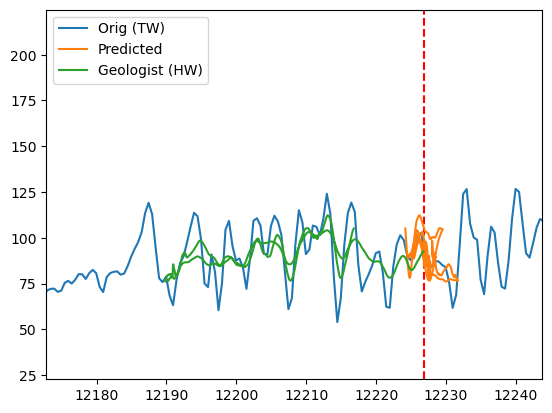

In [859]:
# plt.figure(figsize=(21, 5))
plt.plot(tw['TVT'], tw['GR'], label='Orig (TW)')
tvt0 = evalz['TVT'].iloc[0]
plt.axvline(x=tvt0, color='red', linestyle='--')

plt.plot(final_tvt, evalz['GR'], label='Predicted')
    
plt.plot(evalz['TVT'], evalz['GR'], label='Geologist (HW)')
max_tvt = evalz['TVT'].max()
min_tvt = evalz['TVT'].min()
plt.xlim(min_tvt - 17, max_tvt + 17)
plt.legend()